# 3.0.3-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p9"
subproj <- "AVGUSTINOVA_04_05"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.6

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

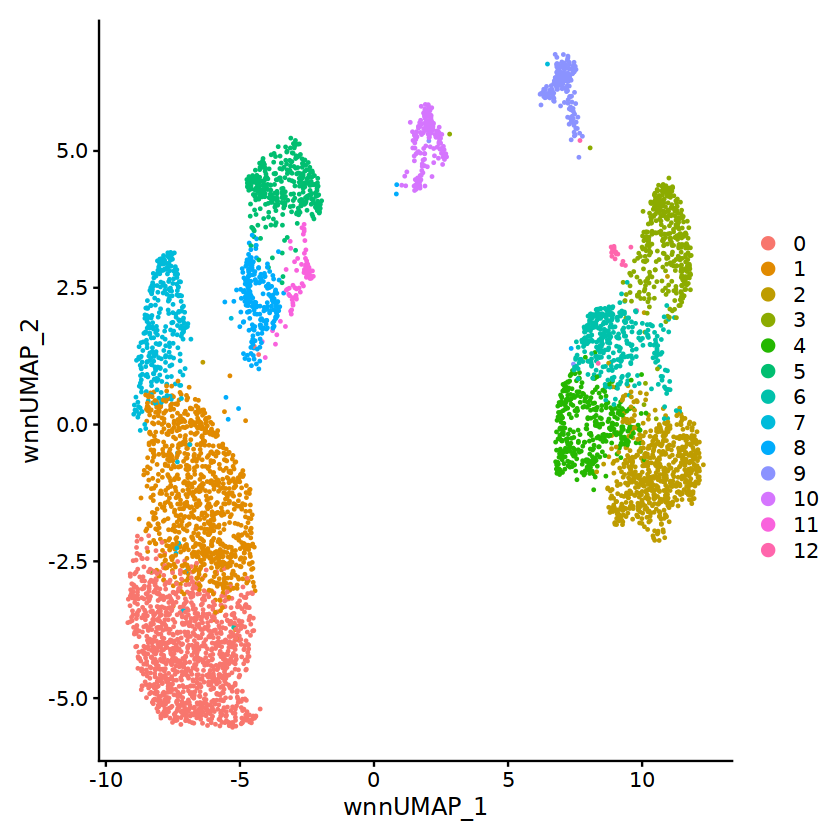

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

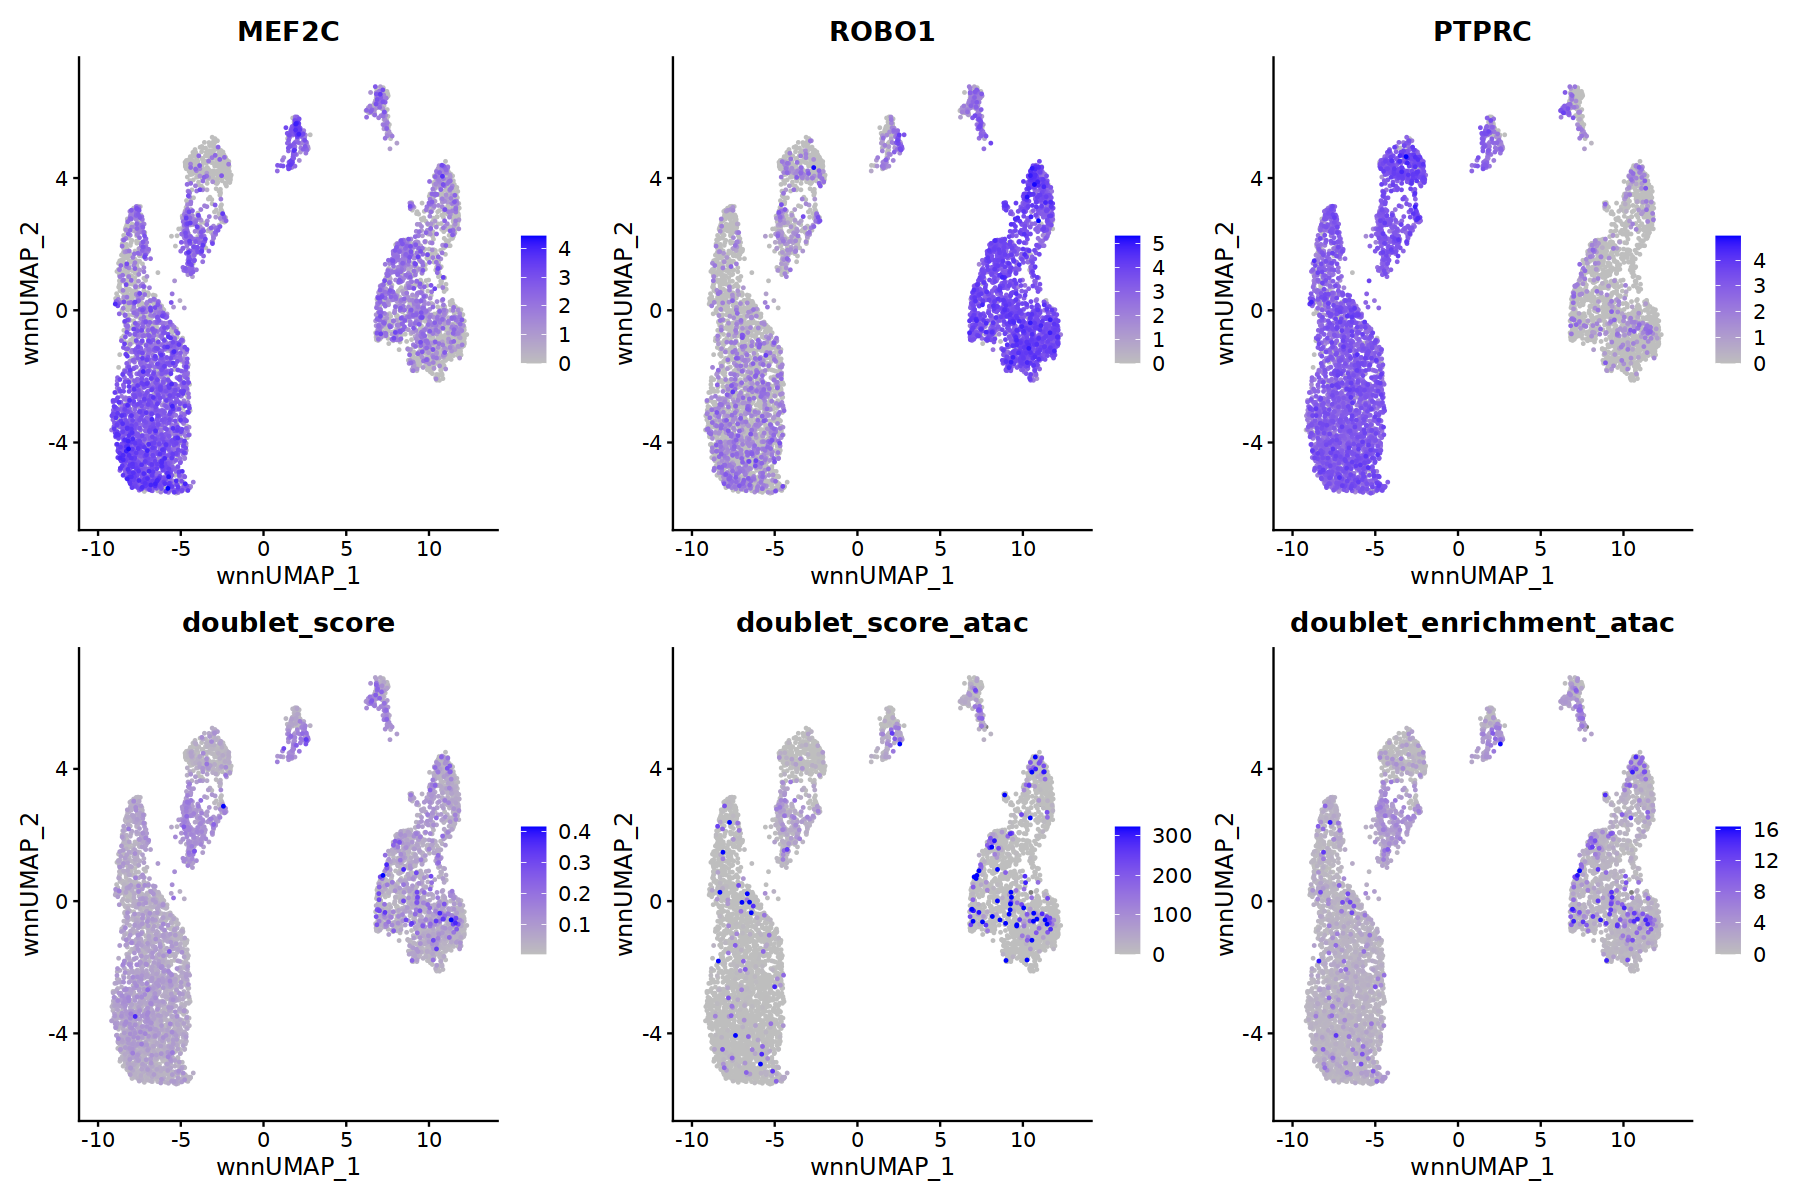

In [11]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MEF2C","ROBO1","PTPRC",
                      "doublet_score","doublet_score_atac","doublet_enrichment_atac"), 
            ncol=3,cols = c("gray", "blue"),  order=T)

## Re-normalize

Check whether DecontX has fixed enough the co-expression of PTPRC and ROBO1

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

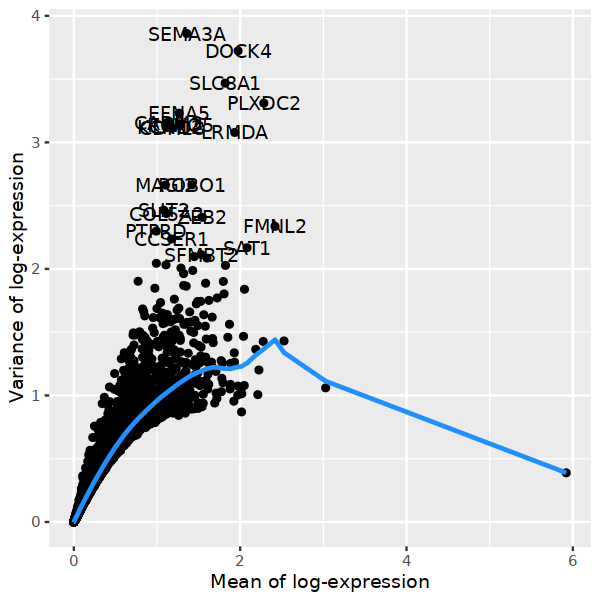

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 791
[1] 791


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  EFNA5, SEMA3A, CDH18, MAGI2, MEIS2, KCND2, SLIT2, COL5A2, FIGN, PTPRD 
	   KCNQ5, MEG8, CADM2, SORBS2, PALLD, ROBO1, ABCA5, PARD3, LTBP1, EGFR 
	   FLRT2, LAMC1, TENM1, NRXN3, DCLK2, KCNT2, MEG3, ANK3, ARHGAP29, RBPMS 
Negative:  DOCK4, PTPRC, SLC8A1, LRMDA, ZEB2, DOCK8, SFMBT2, RGS1, DOCK10, ARHGAP15 
	   QKI, CELF2, FYB1, MEF2A, LDLRAD4, TRPS1, HIF1A, ATXN1, PLXDC2, ARHGAP26 
	   CTSB, MIR181A1HG, DLEU1, CHST11, MAML2, RAB31, SAMSN1, GNA13, LYN, HLA-DRB1 
PC_ 2 
Positive:  KCNMA1, FMNL2, CCSER1, CDH18, KCND2, RTTN, CADM2, NRG1, TENM1, NRXN3 
	   AC092691.1, SEMA3A, LTBP1, SAT1, ABCA5, AC108515.1, RBBP8, ADAMTSL1, TGFBR3, TMEFF2 
	   DPH6, LINC02057, ROBO2, BMP5, ARHGAP29, NR5A2, EPHA4, HAPLN1, AC098617.1, PCDH15 
Negative:  CDH11, SULF1, CALD1, MIR100HG, ZFPM2, IGFBP7, PRKG1, COL6A3, LDB2, FAP 
	   DNM3OS, BICC1, FAM155A, RBMS3, COL4A2, POSTN, TSHZ2, ADAMTS12, CACNA2D1, CACNA1C 
	   PBX1, ZNF521, THBS2, DCN, MEIS1, LGR4, SVIL, COL8

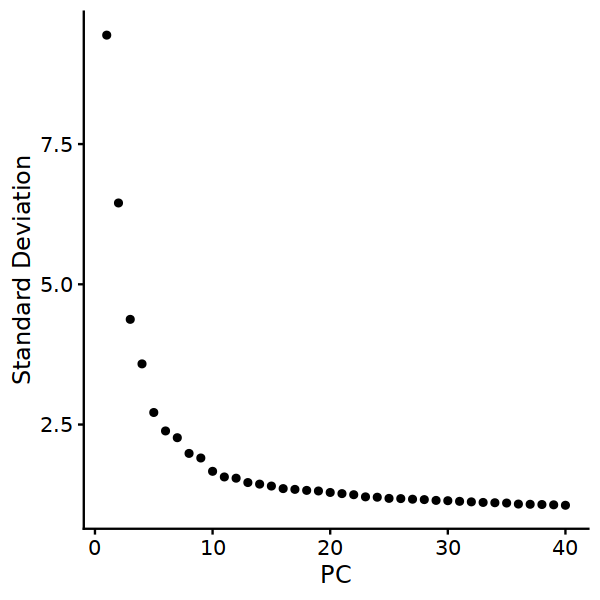

In [19]:
ElbowPlot(seurat_obj, n=40)

In [20]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
  assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


15:01:50 UMAP embedding parameters a = 0.9922 b = 1.112

15:01:50 Read 5182 rows and found 15 numeric columns

15:01:50 Using Annoy for neighbor search, n_neighbors = 30

15:01:50 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:01:50 Writing NN index file to temp file /scratch_tmp/49729482/RtmppdRXdN/file1462275c6c09f

15:01:50 Searching Annoy index using 1 thread, search_k = 3000

15:01:52 Annoy recall = 100%

15:01:53 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:01:54 Initializing from normalized Laplacian + noise (using irlba)

15:01:54 Commencing optimization for 500 epochs, with 206738 positive edges

15:02:09 Optimization finished



In [21]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [22]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

15:02:23 UMAP embedding parameters a = 0.115 b = 1.929

15:02:23 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:02:25 Initializing from normalized Laplacian + noise (using irlba)

15:02:25 Commencing optimization for 500 epochs, with 149462 positive edges

15:02:41 Optimization finished



In [23]:
markers = c("MEF2C","ROBO1","POSTN", "COL6A3","SEMA3A","PTPRC")

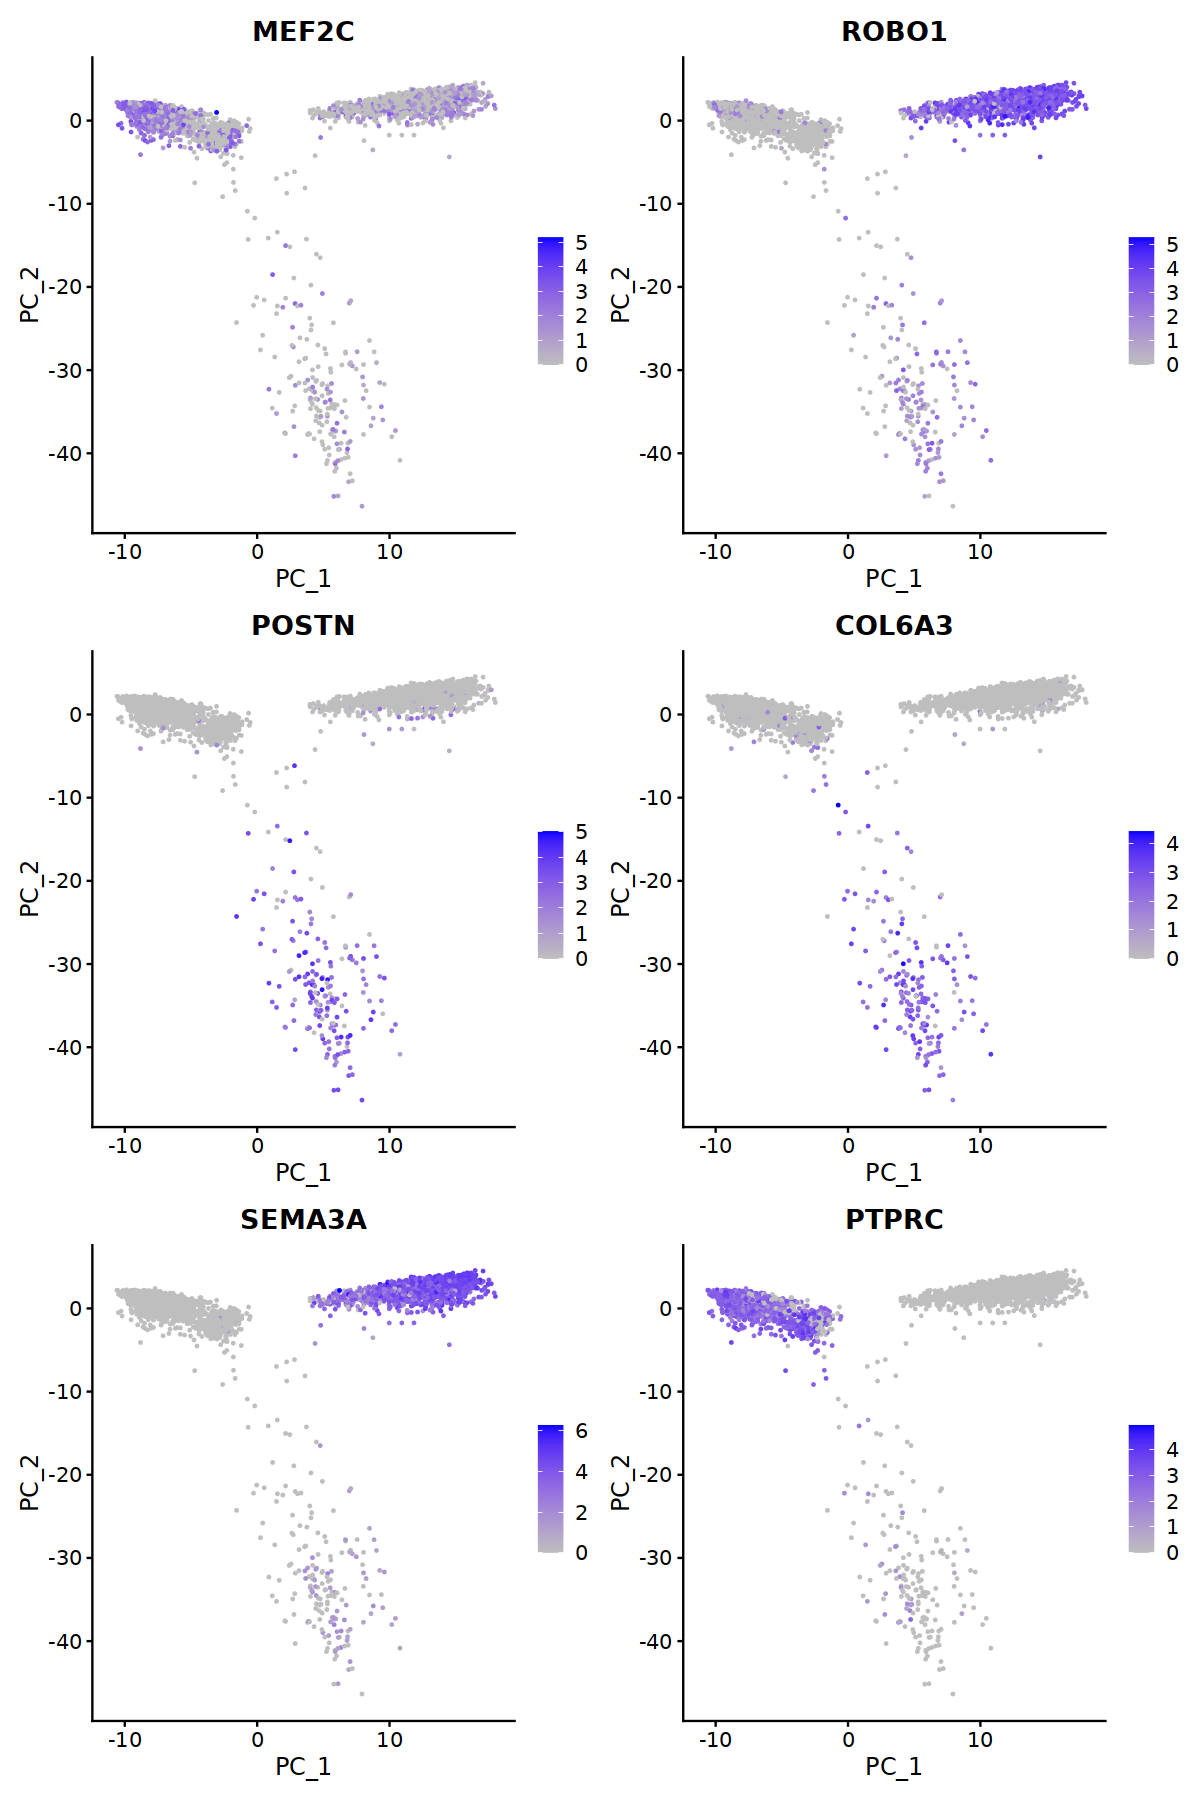

In [24]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "pca", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

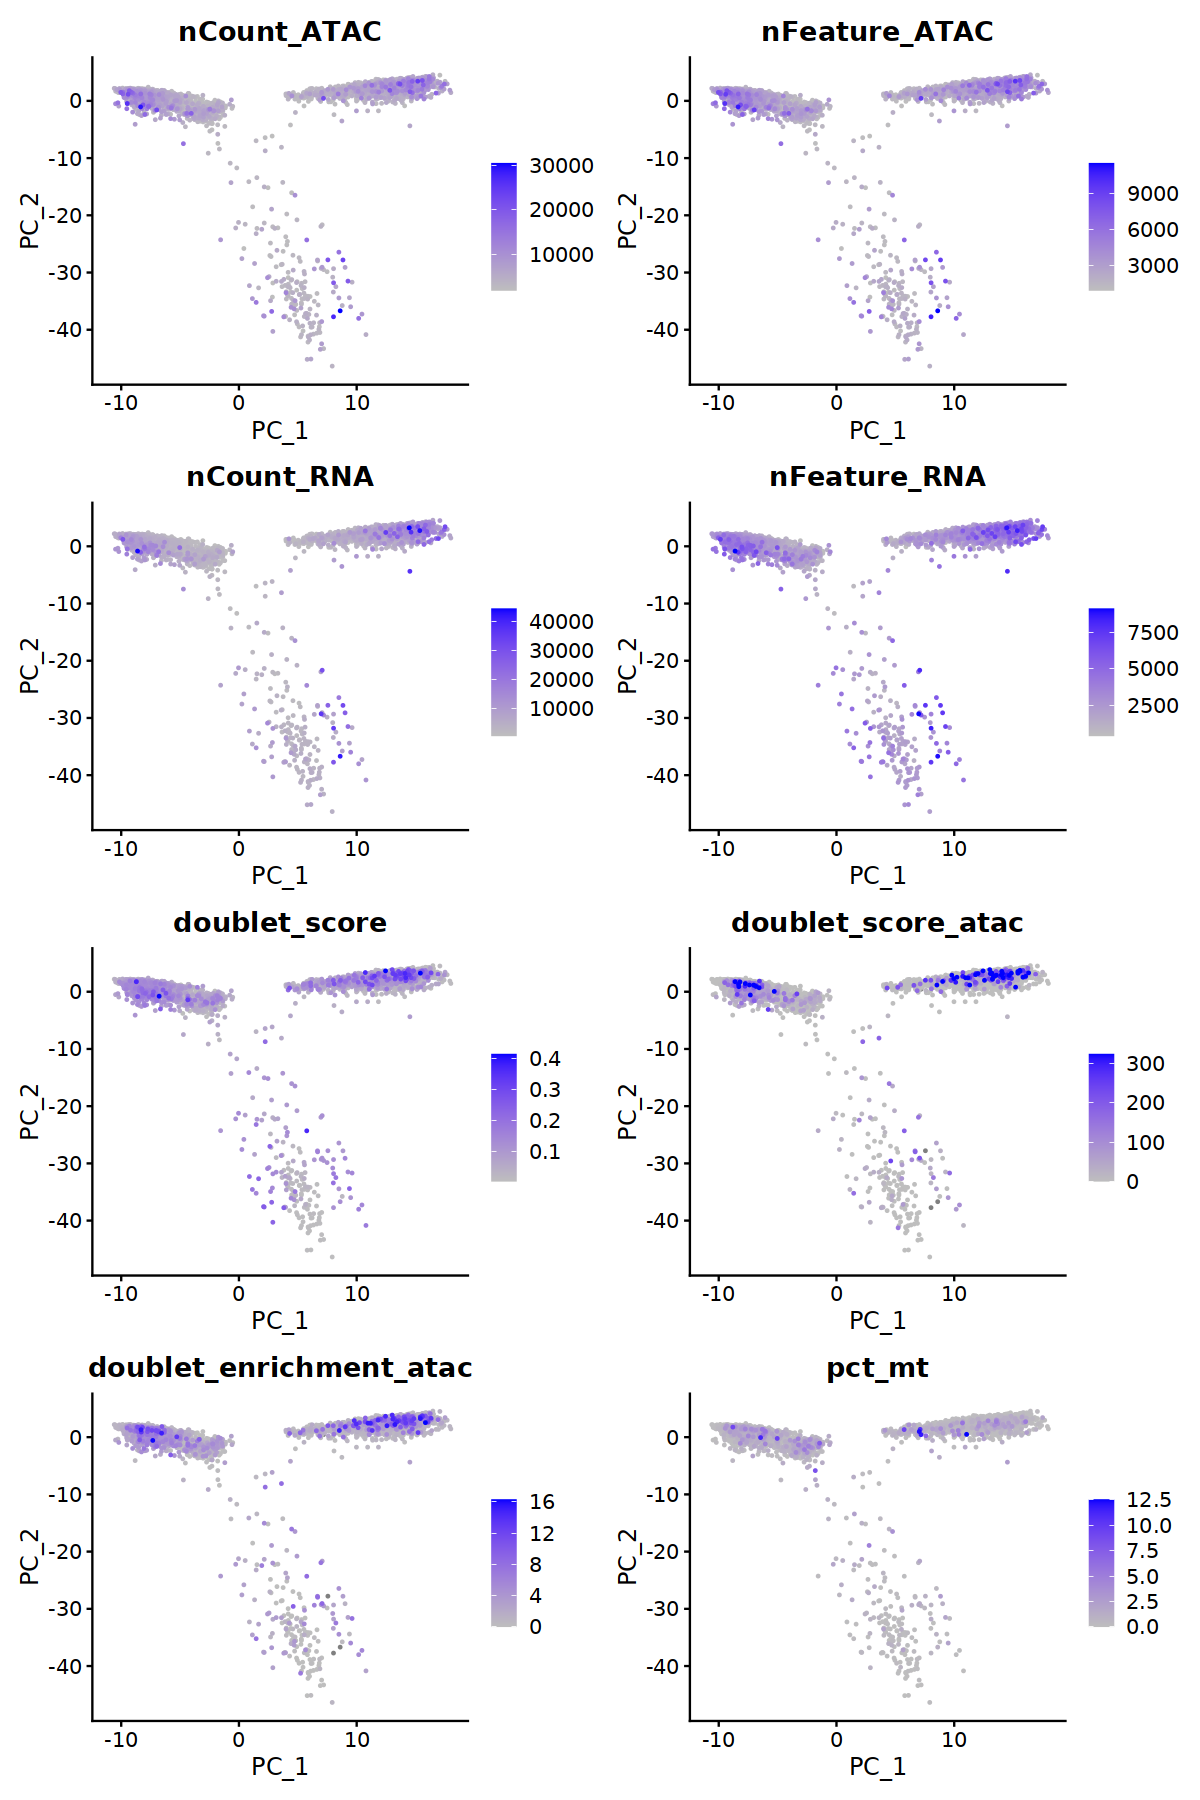

In [25]:
options(repr.plot.width = 10, repr.plot.height = 15)

qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")

FeaturePlot(seurat_obj, reduction = "pca", 
            feature=qc_vars, ncol=2,
            cols = c("gray", "blue"),  order=T)

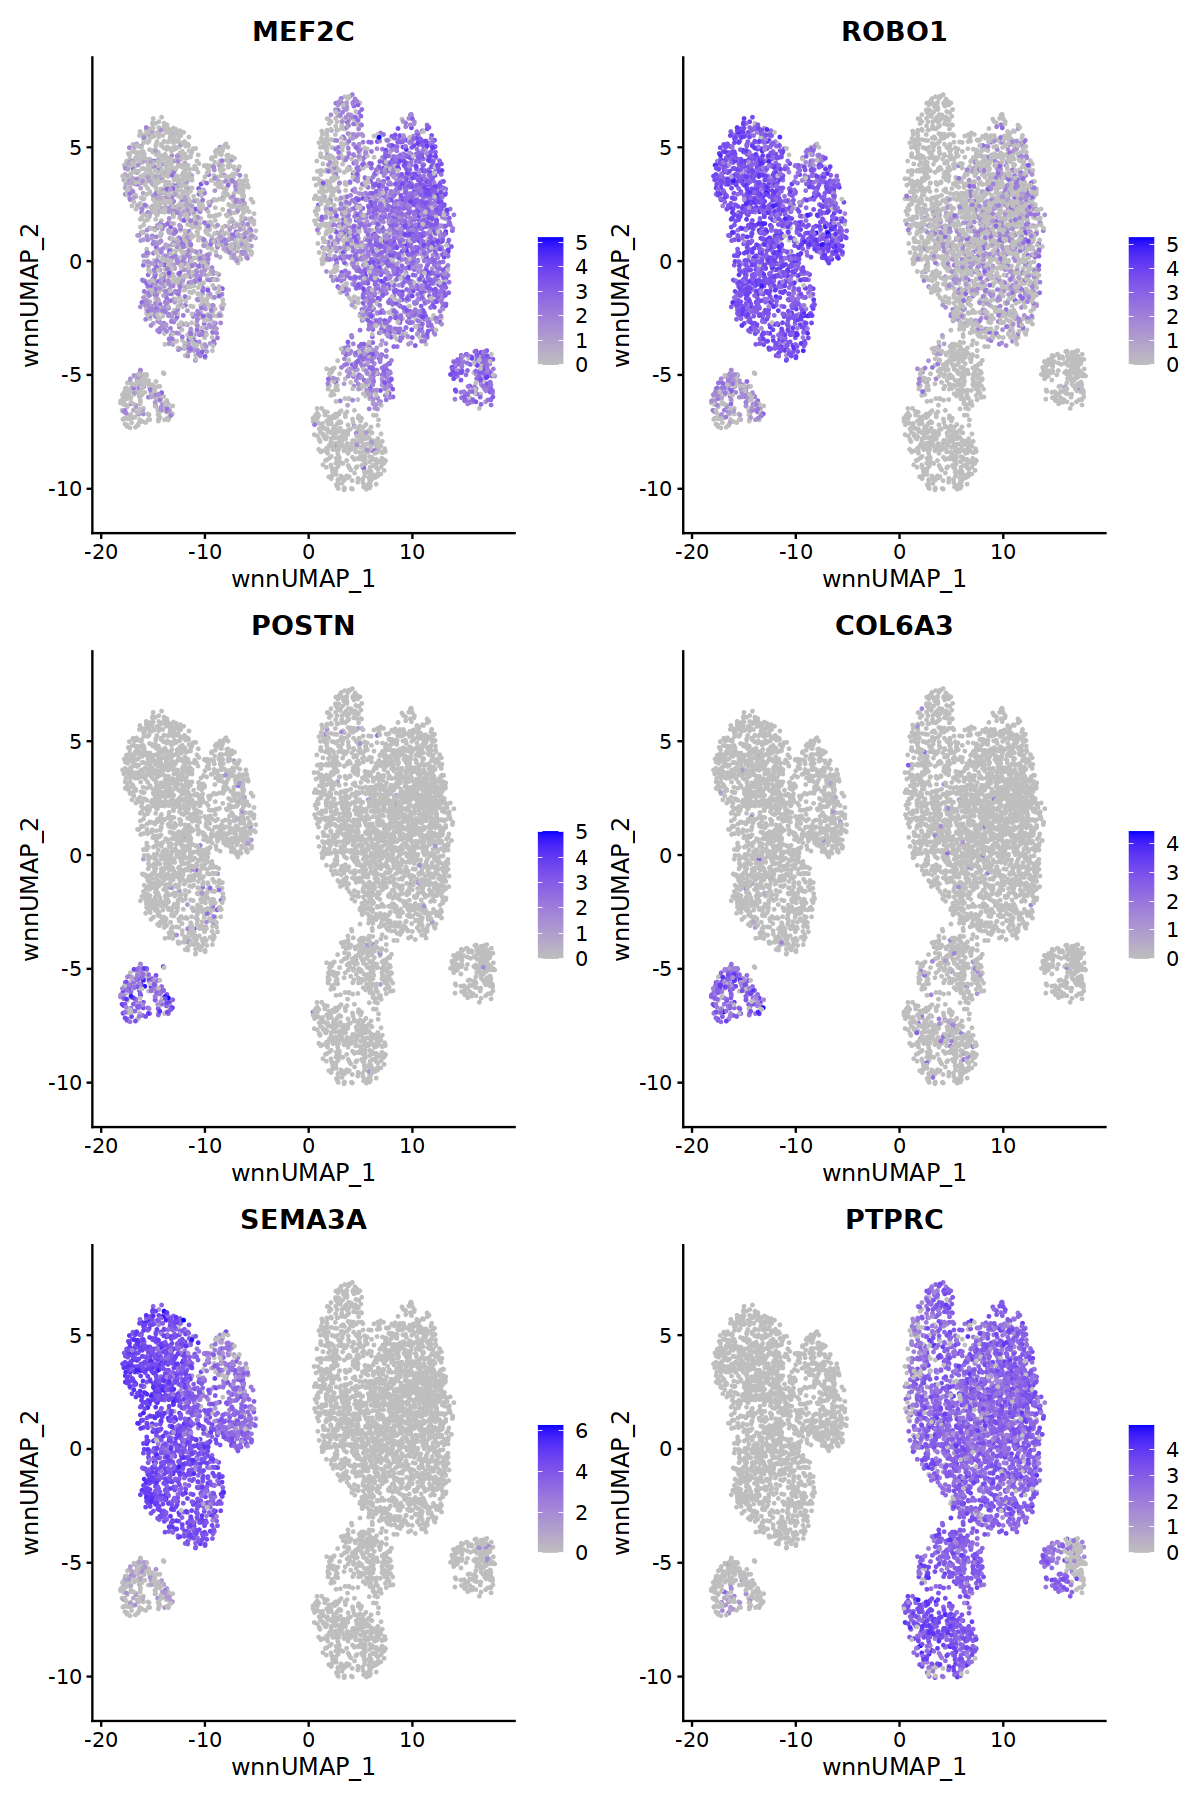

In [26]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

In [27]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5182
Number of edges: 175838

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9690
Number of communities: 6
Elapsed time: 0 seconds


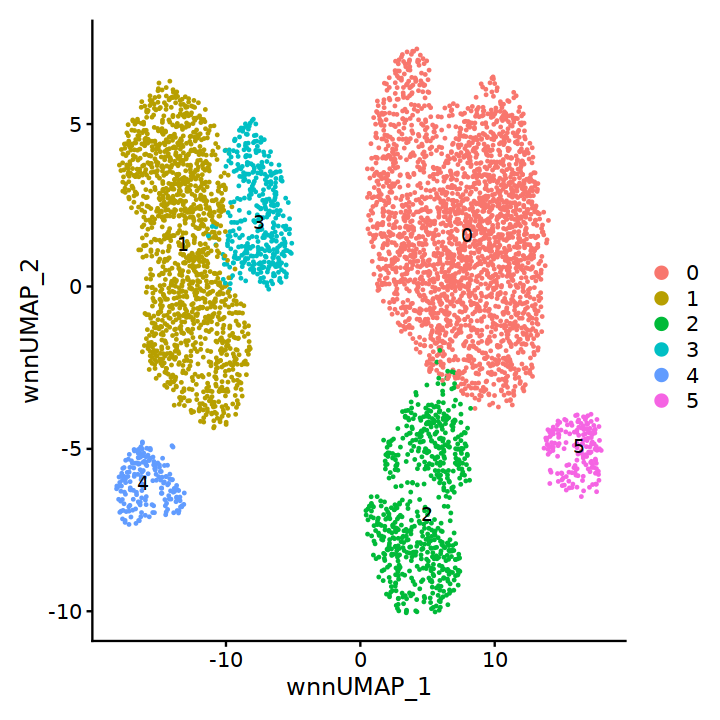

In [28]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

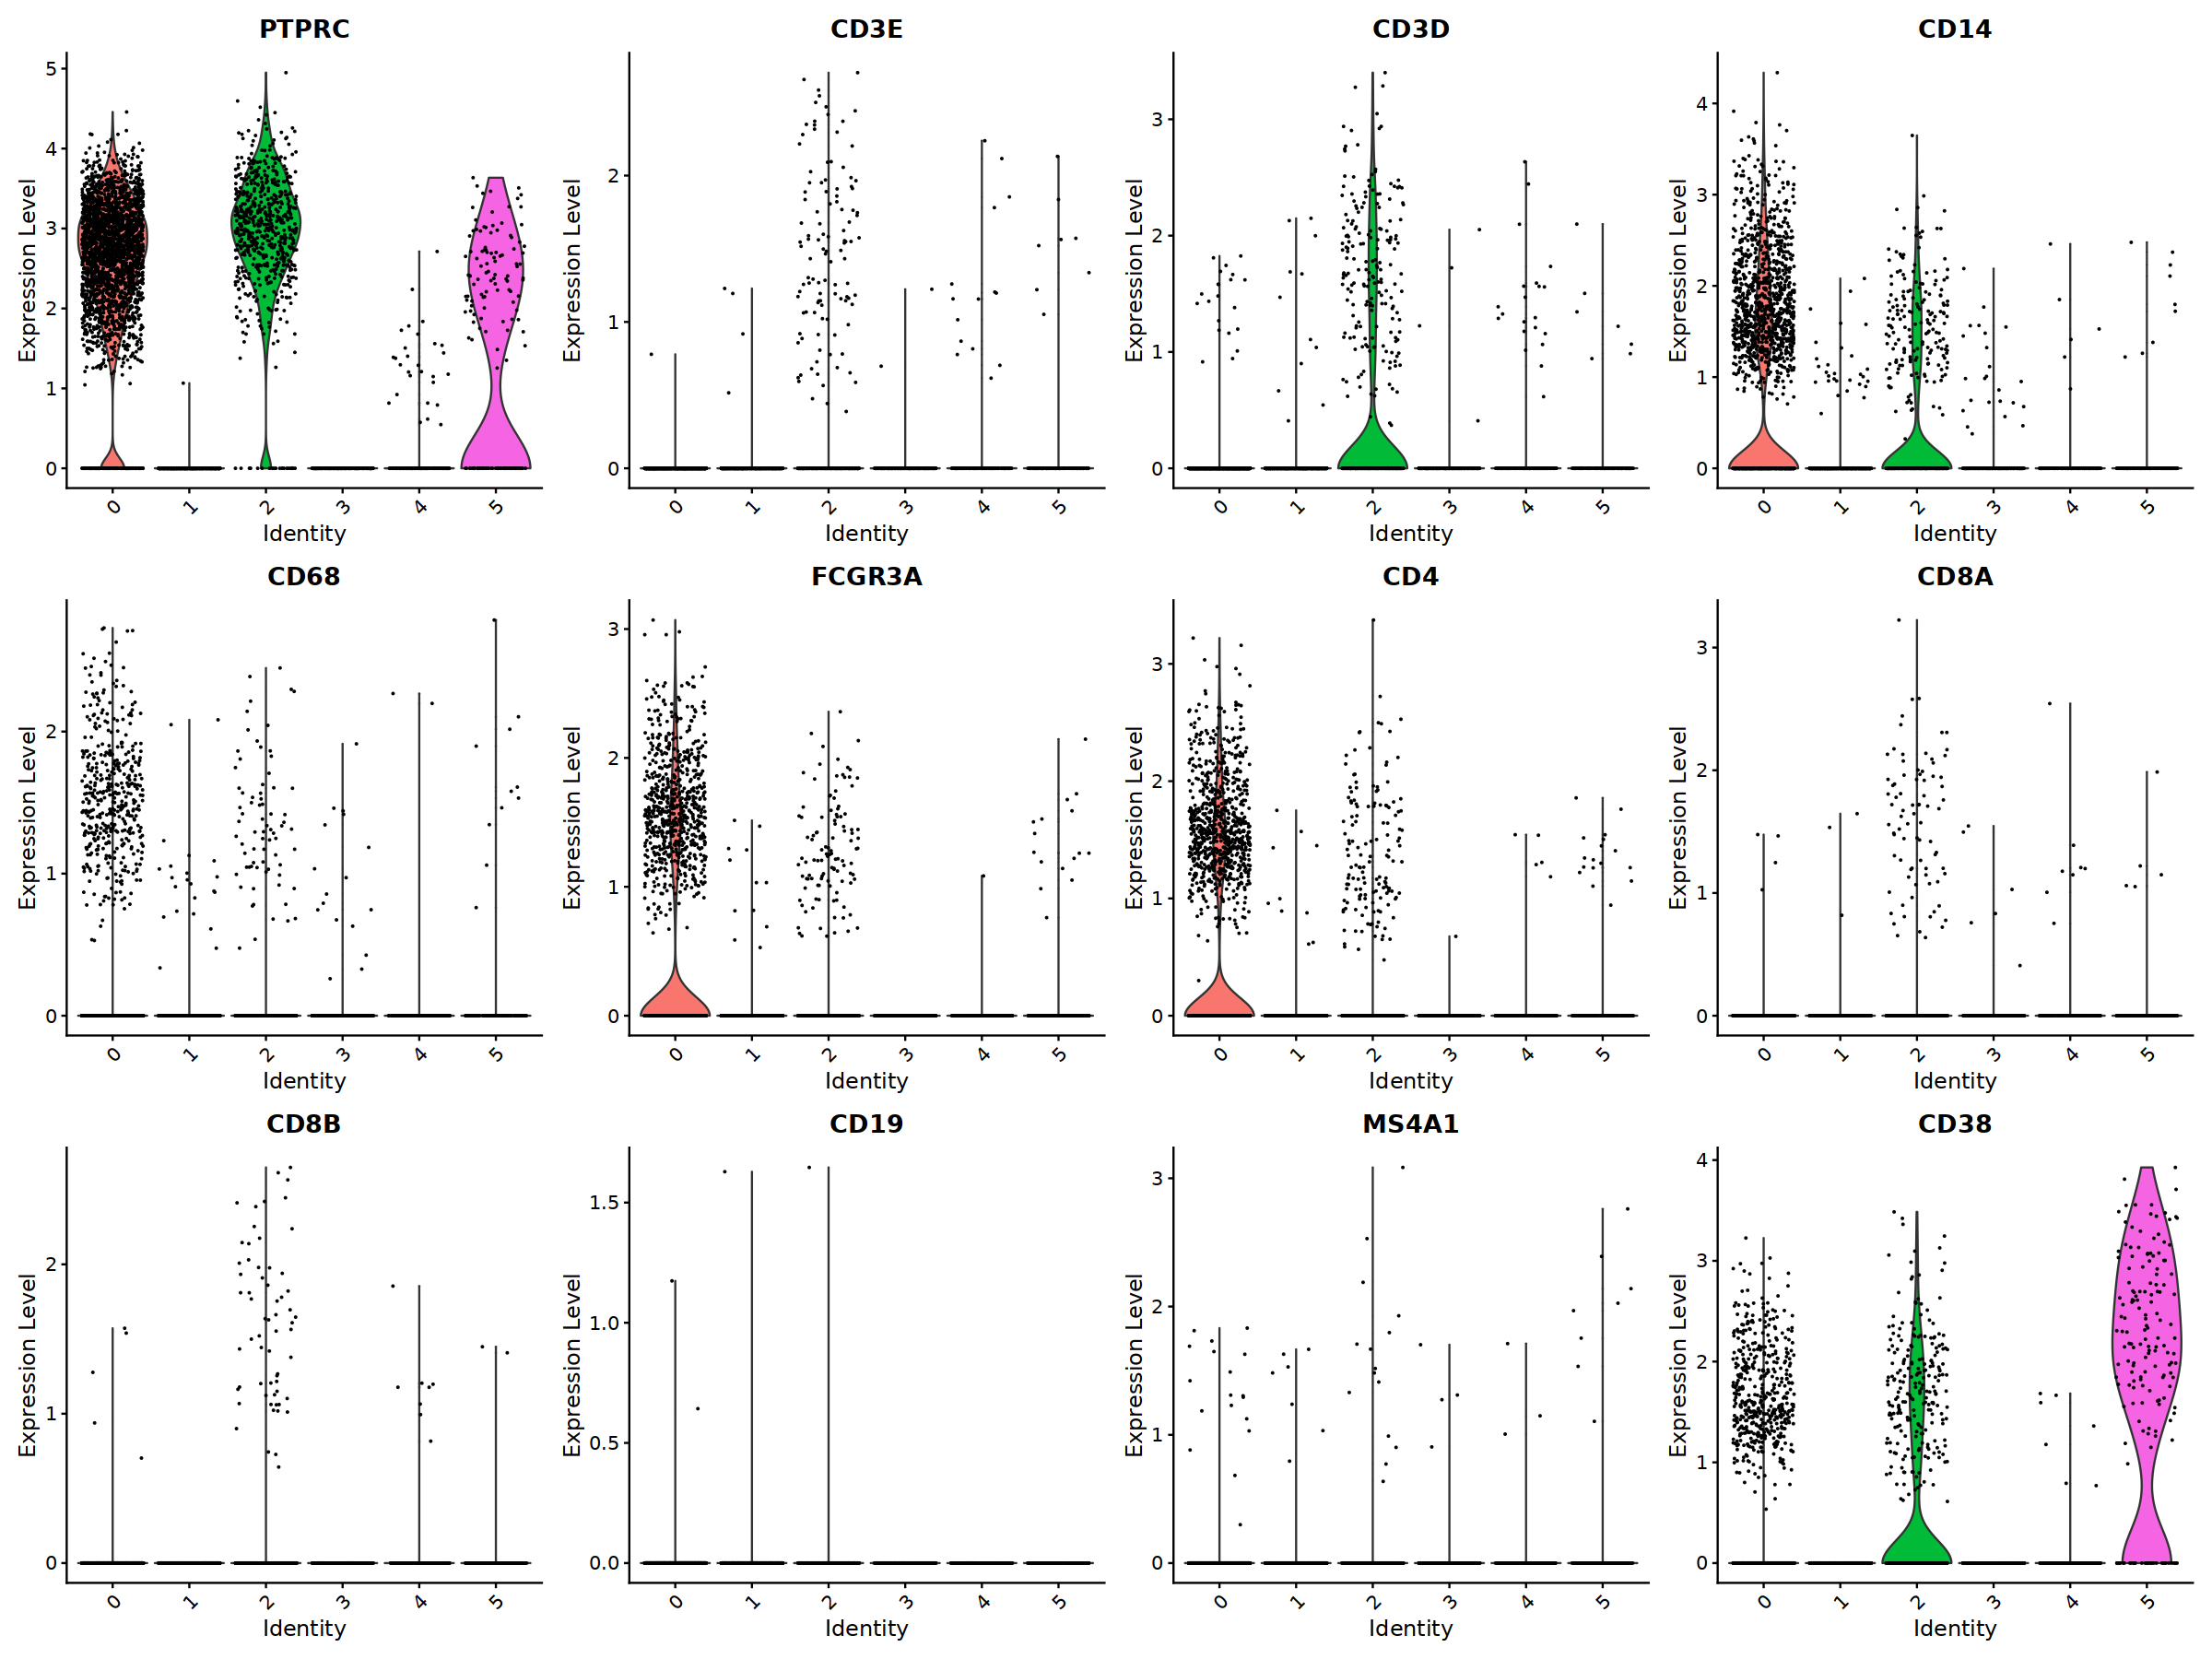

In [29]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", 
            "CD4", "CD8A", "CD8B", "CD19", "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)


VlnPlot(seurat_obj,feature=vars2plot, ncol = 4)

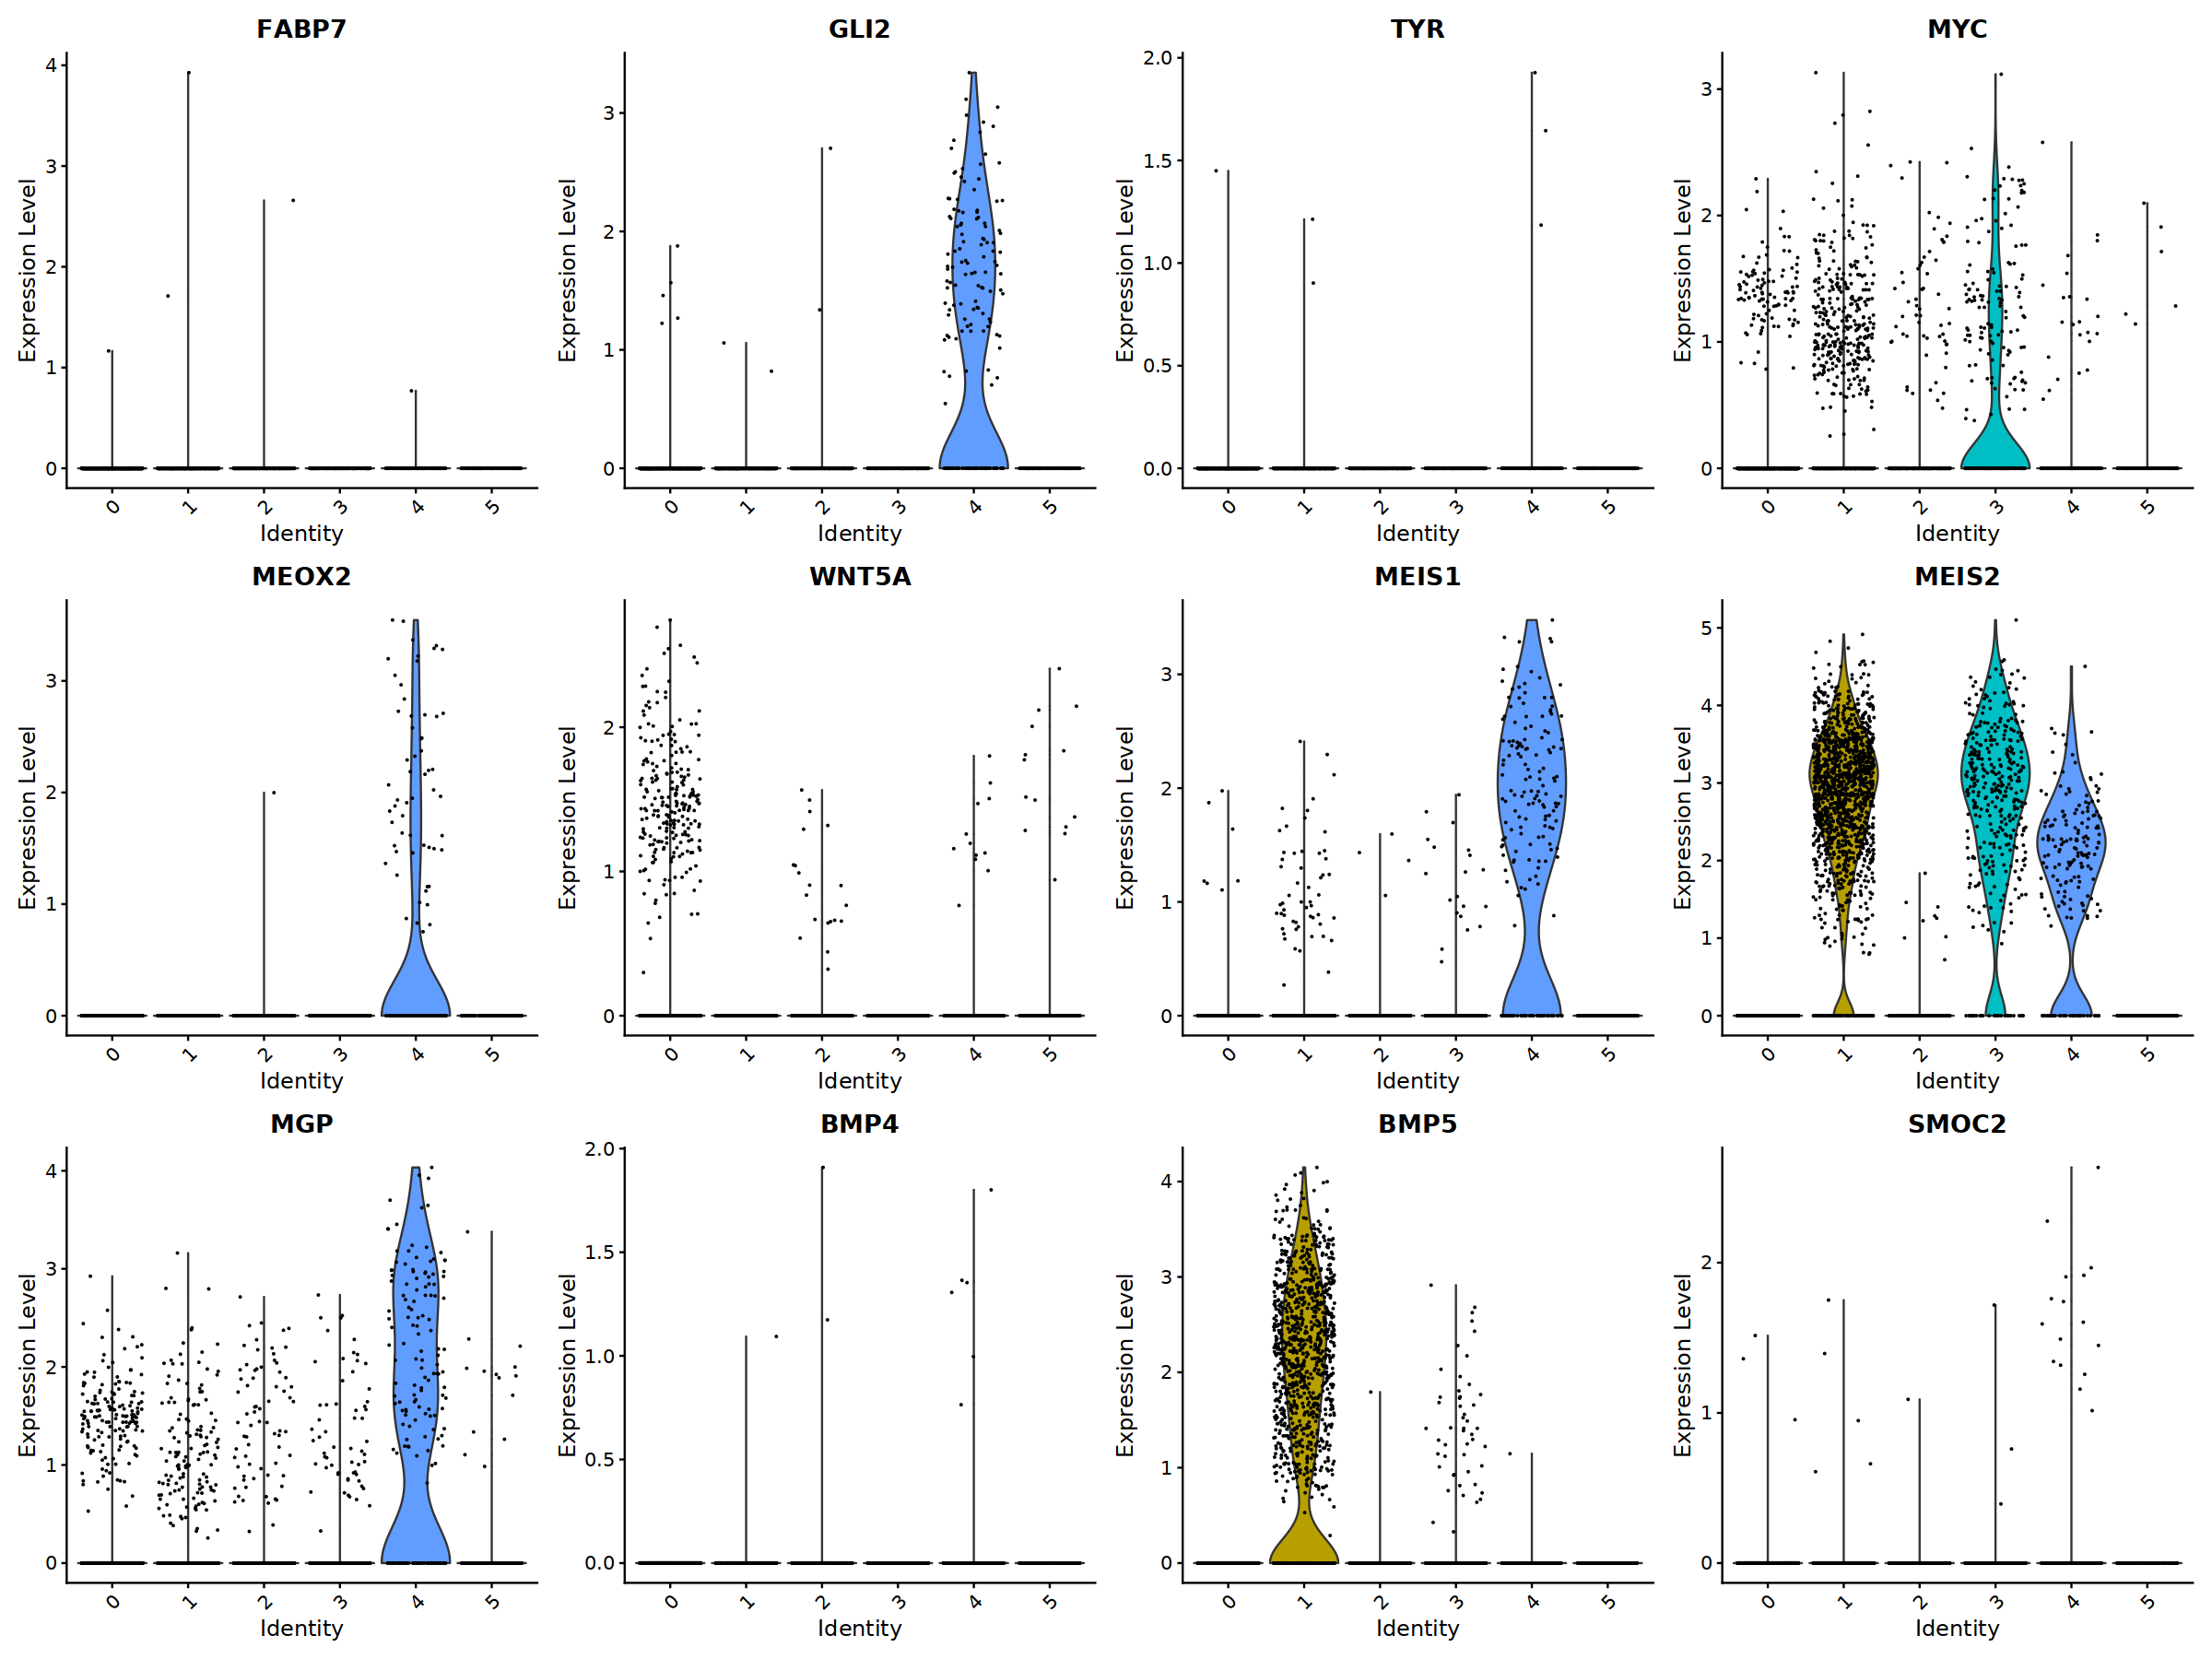

In [30]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

VlnPlot(seurat_obj,feature=vars2plot, ncol = 4)

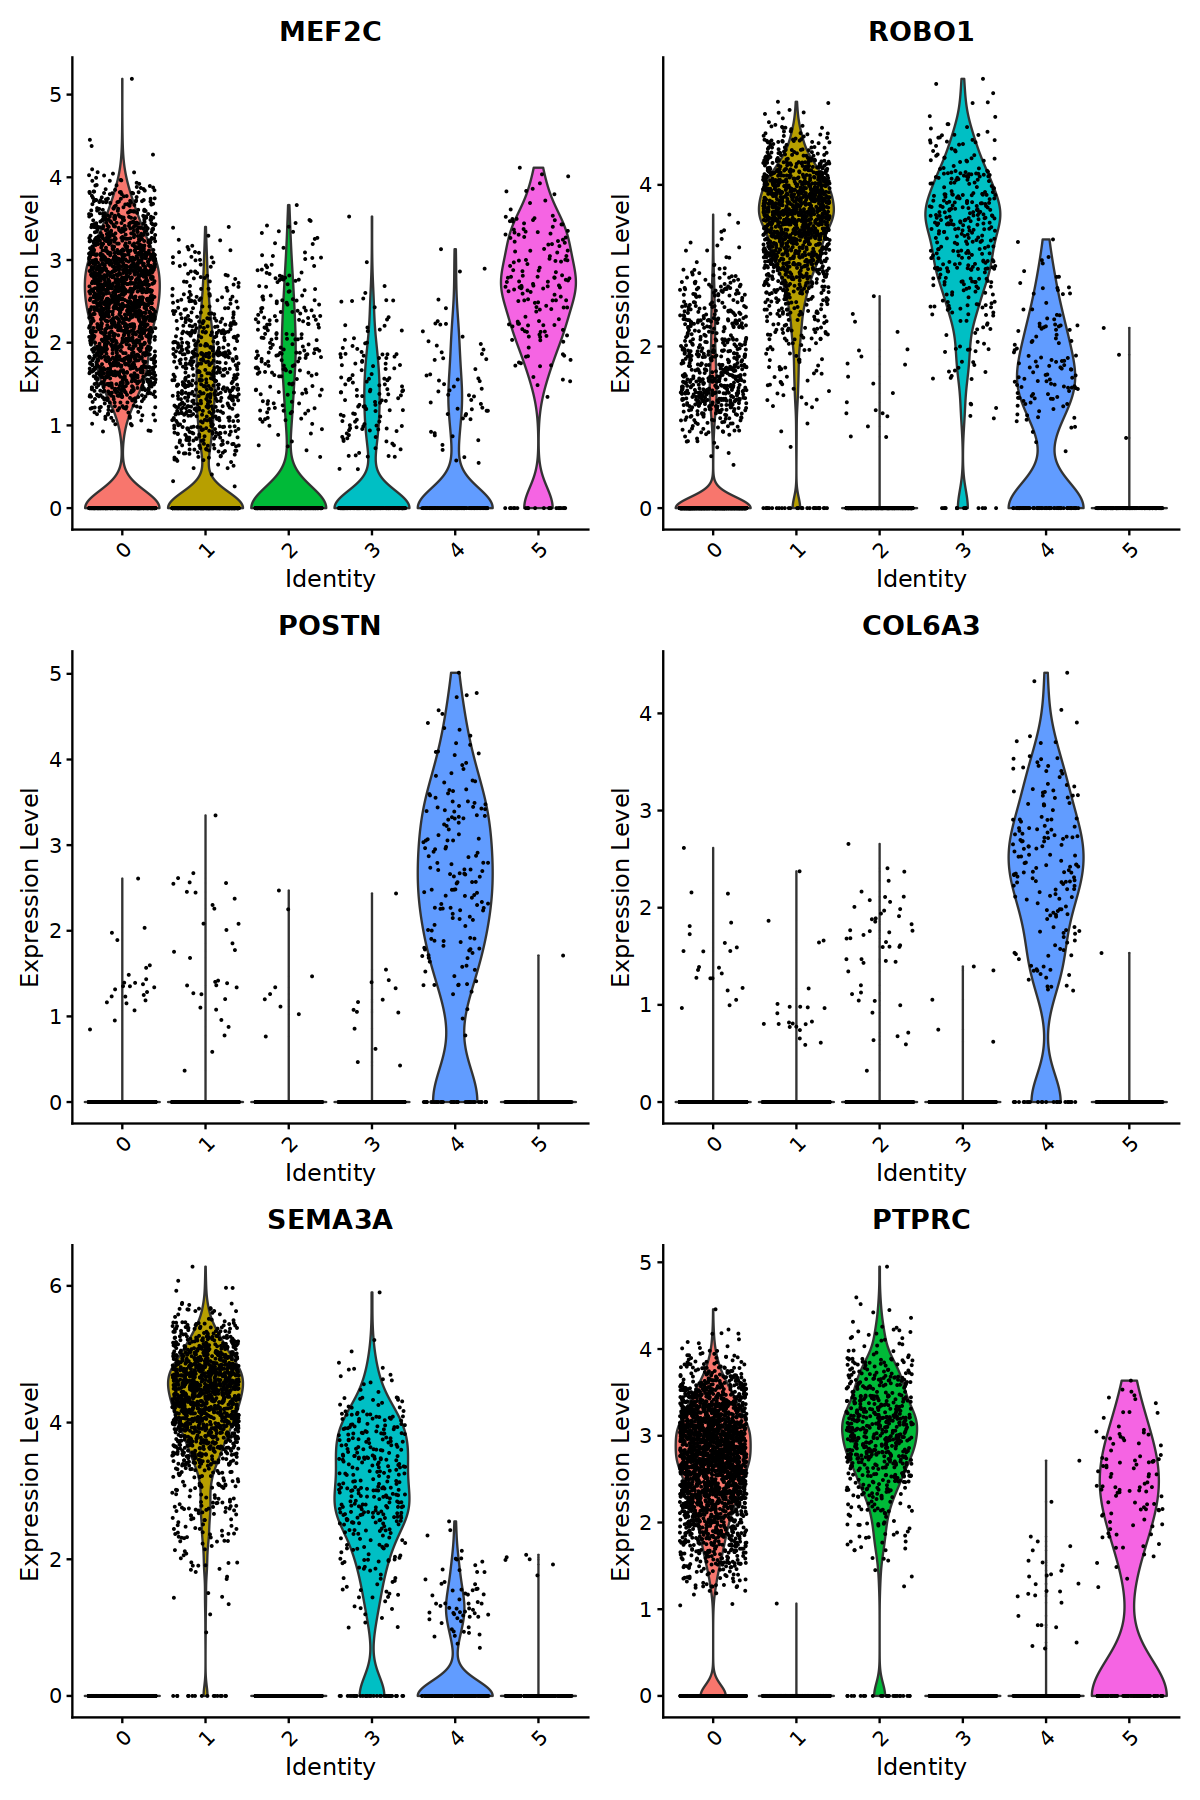

In [31]:
options(repr.plot.width = 10, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=markers, ncol=2)

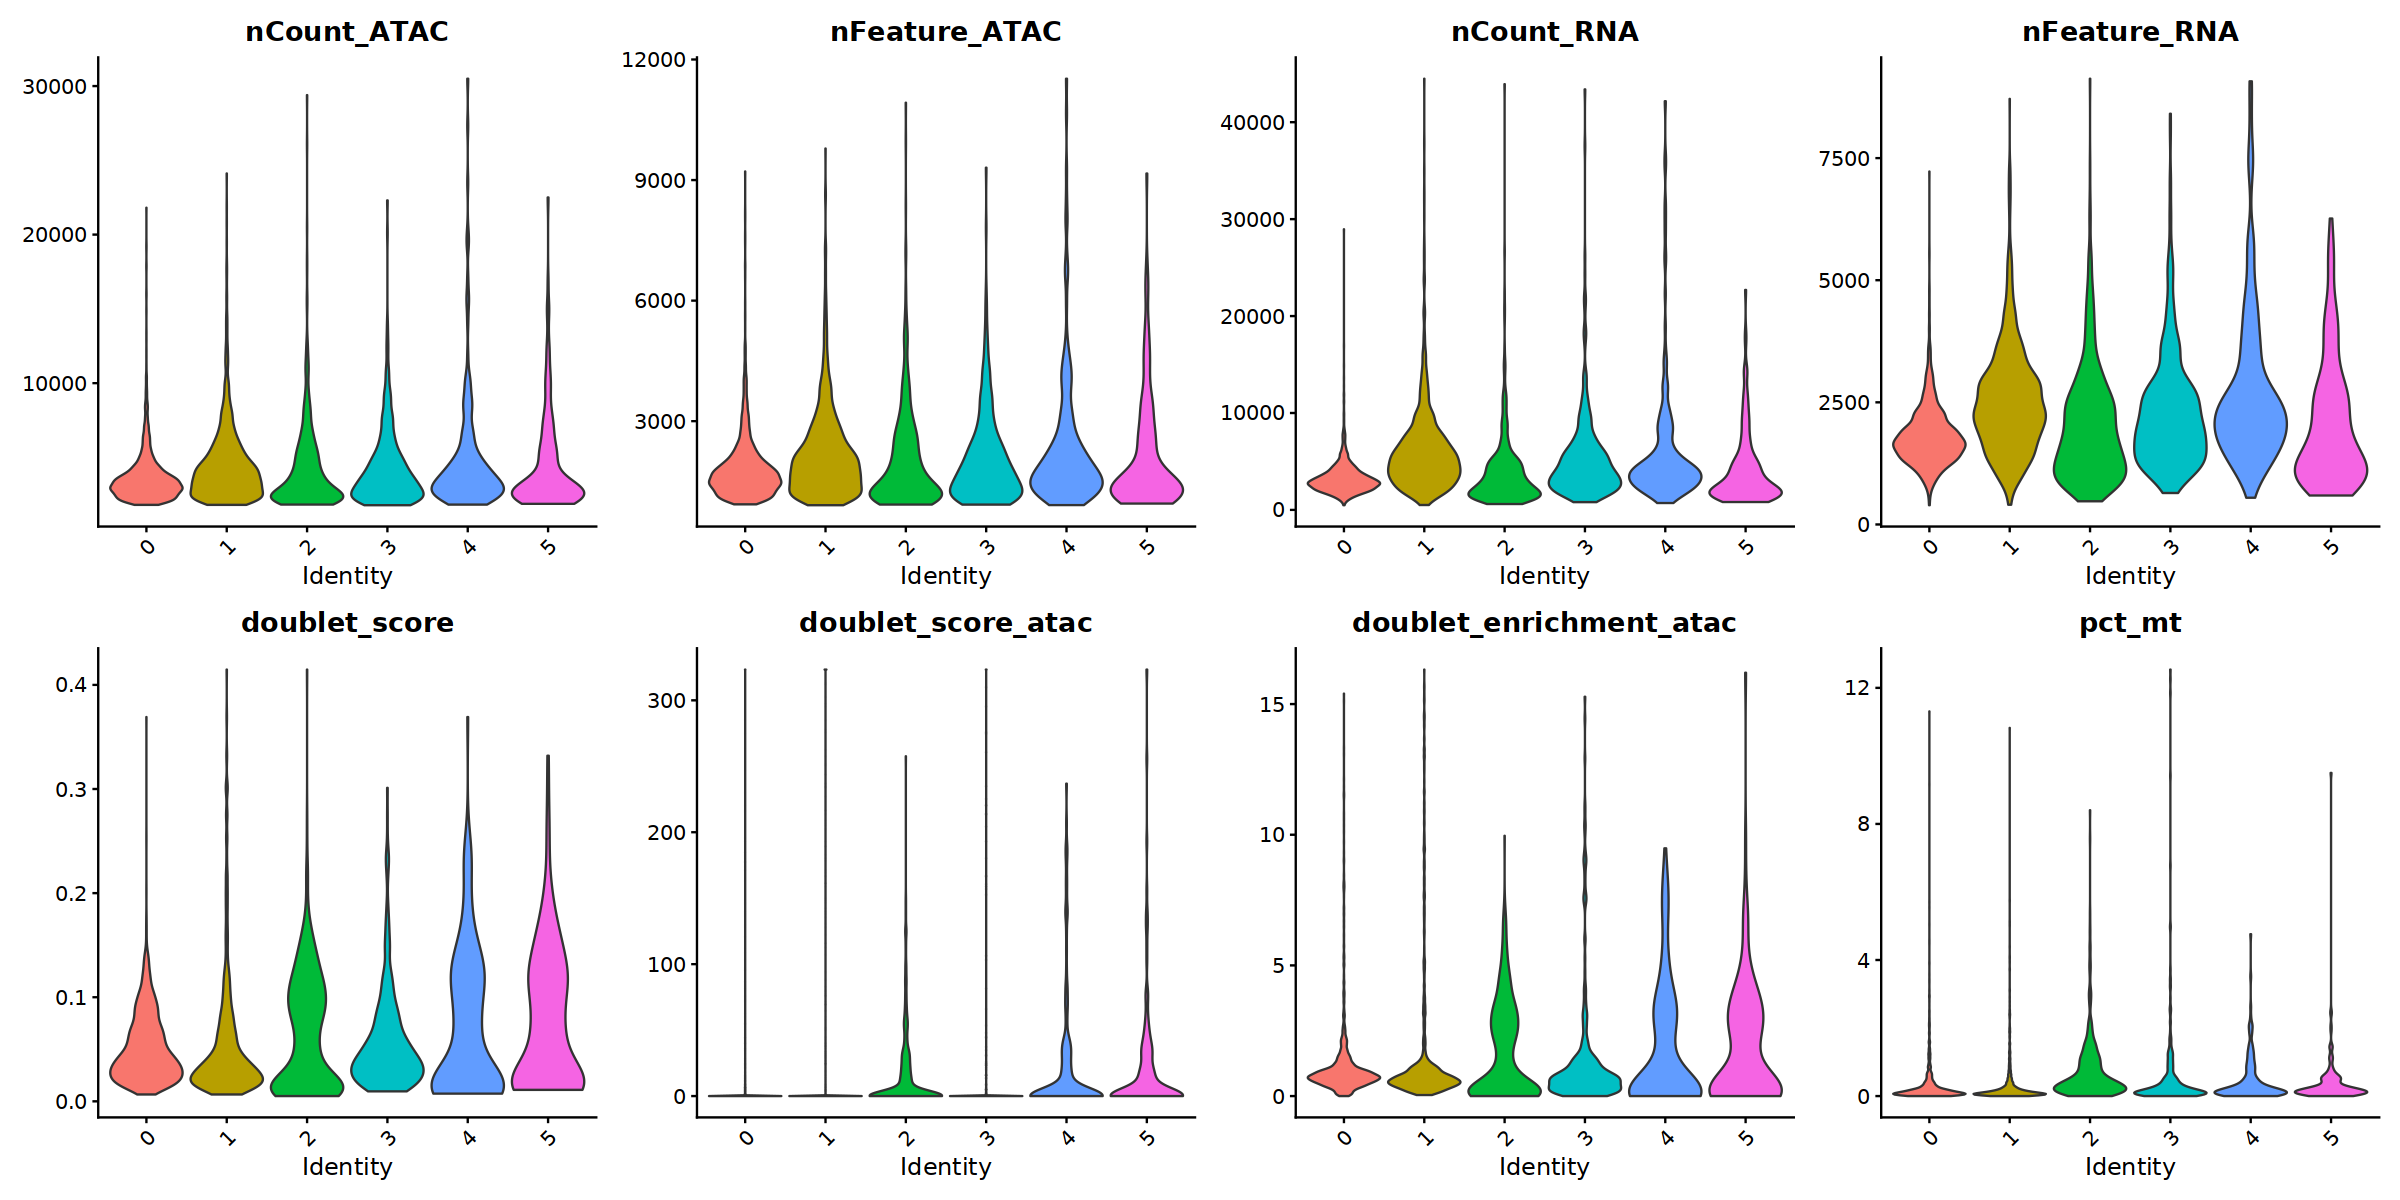

In [32]:
options(repr.plot.width = 20, repr.plot.height = 10)

VlnPlot(seurat_obj,  feature=qc_vars, ncol = 4, pt.size = 0)

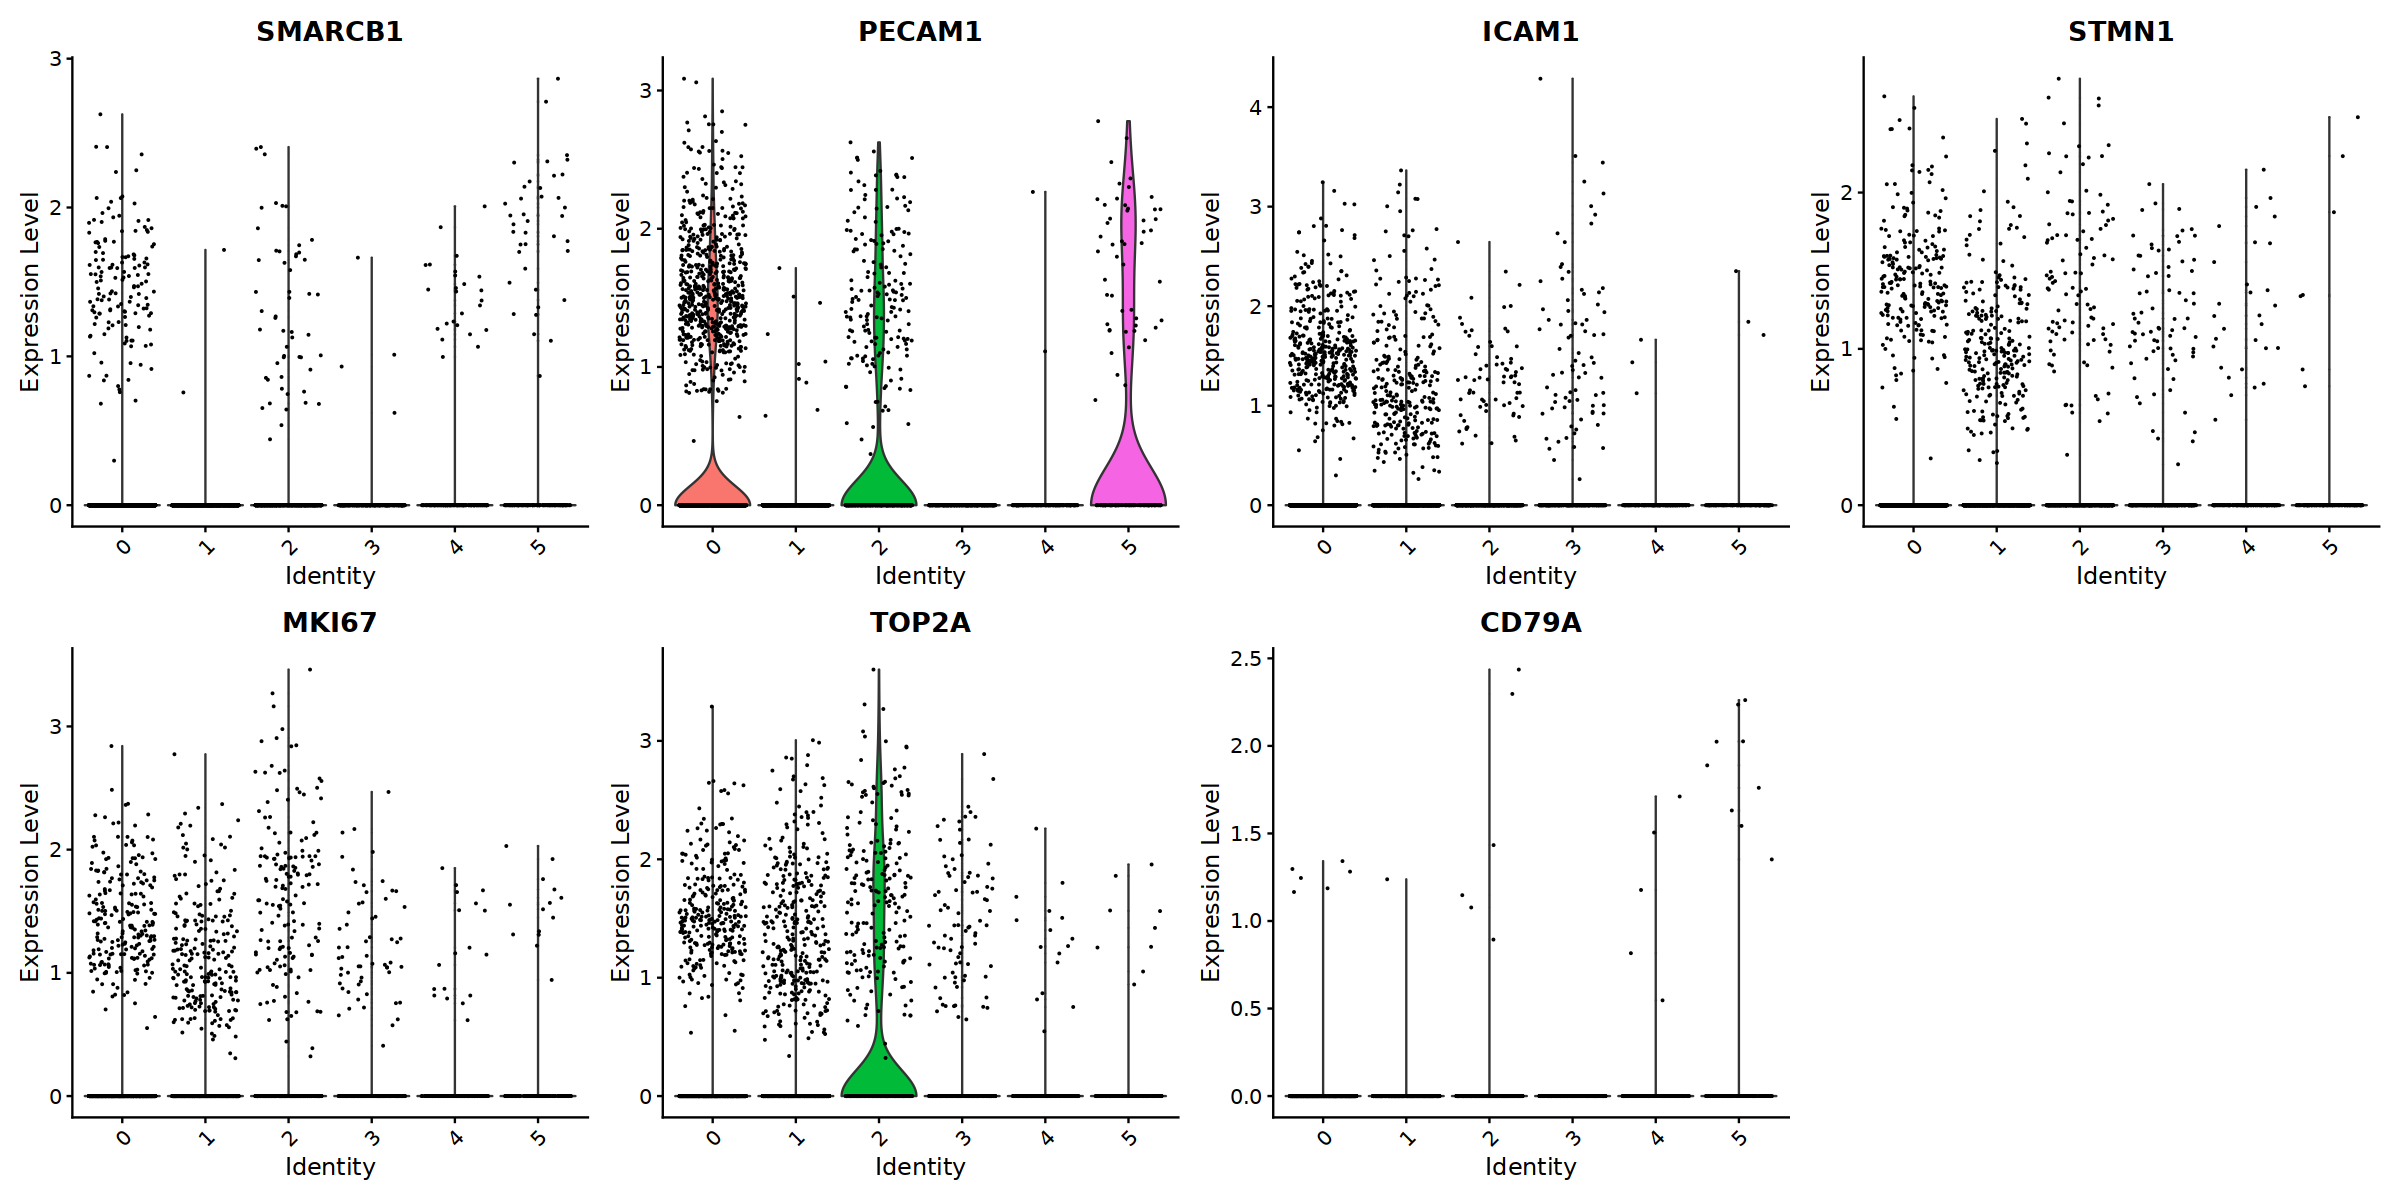

In [33]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A", "CD79A")


VlnPlot(seurat_obj, feature=other, ncol = 4)

In [34]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5



Cluster 0 has a mixture of markers

In [35]:
rna.markers %>% 
  dplyr::filter(cluster == "0") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
DOCK4,0.000000e+00,3.513160,0.986,0.132,0.000000e+00,0,DOCK4
SLC8A1,0.000000e+00,3.508987,0.961,0.119,0.000000e+00,0,SLC8A1
LRMDA,0.000000e+00,3.181884,0.975,0.251,0.000000e+00,0,LRMDA
ZEB2,0.000000e+00,2.877576,0.935,0.183,0.000000e+00,0,ZEB2
PLXDC2,0.000000e+00,2.815802,0.984,0.366,0.000000e+00,0,PLXDC2
LNCAROD,0.000000e+00,2.677438,0.699,0.075,0.000000e+00,0,LNCAROD
SLC16A10,2.520034e-302,2.649357,0.530,0.068,7.580011e-298,0,SLC16A10
MITF,0.000000e+00,2.613494,0.702,0.092,0.000000e+00,0,MITF
FMN1,0.000000e+00,2.522359,0.732,0.088,0.000000e+00,0,FMN1


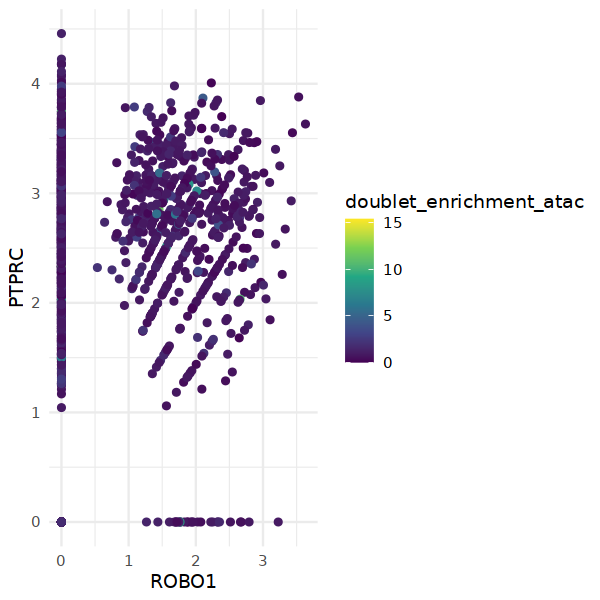

In [36]:
options(repr.plot.width = 5, repr.plot.height = 5)
data <- FetchData(seurat_obj, vars = c("seurat_clusters",
                                       "doublet_enrichment_atac", markers))
data <- data[data$seurat_clusters == 0, ]
ggplot(data, aes(x = ROBO1, y = PTPRC, color = doublet_enrichment_atac)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

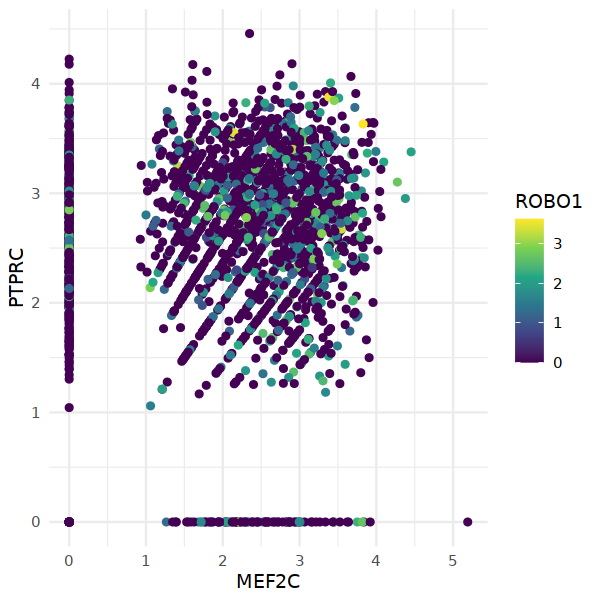

In [37]:
ggplot(data, aes(x = MEF2C, y = PTPRC, color = ROBO1)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

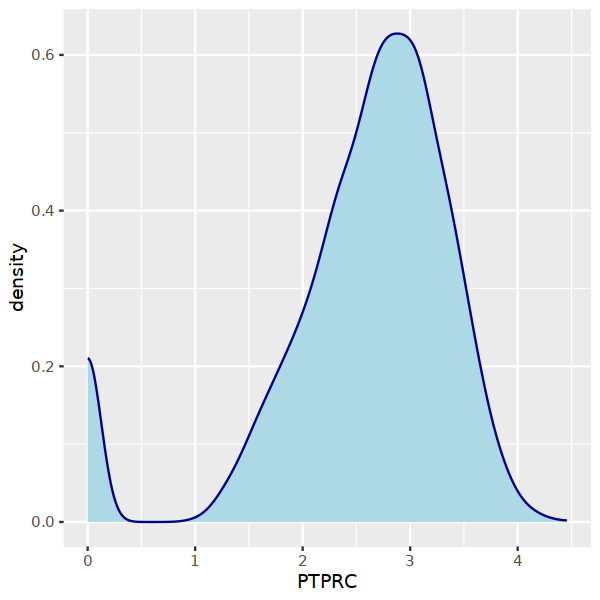

In [38]:
ggplot(data, aes(x=PTPRC))+
  geom_density(color="darkblue", fill="lightblue")

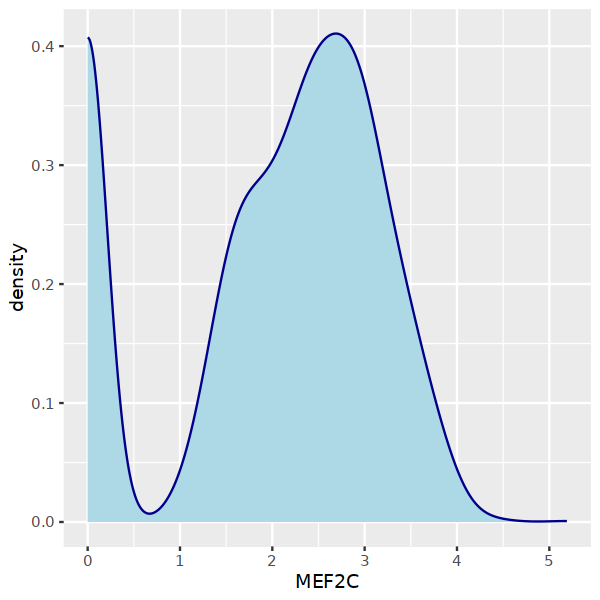

In [39]:
ggplot(data, aes(x=MEF2C))+
  geom_density(color="darkblue", fill="lightblue")

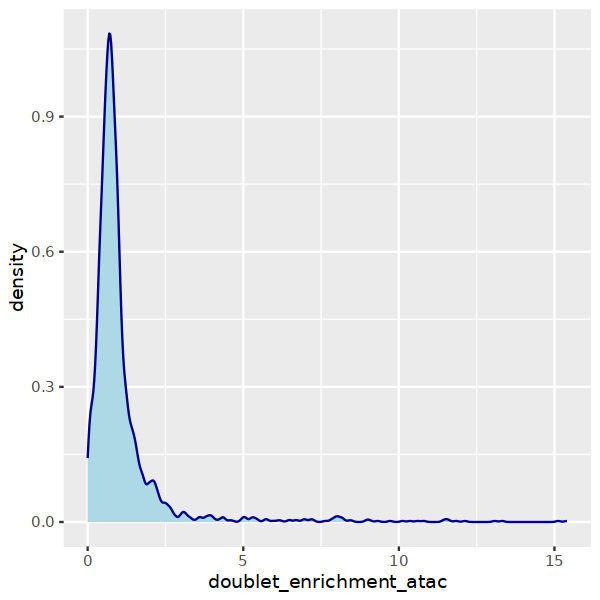

In [40]:
ggplot(data, aes(x=doublet_enrichment_atac))+
  geom_density(color="darkblue", fill="lightblue")

In [41]:
rna.markers %>% 
  dplyr::filter(cluster == "4") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
SULF1,0.000000e+00,5.208740,0.899,0.000,0.000000e+00,4,SULF1
CDH11,0.000000e+00,4.804563,0.926,0.001,0.000000e+00,4,CDH11
CALD1,0.000000e+00,4.600348,0.926,0.017,0.000000e+00,4,CALD1
PRKG1,0.000000e+00,4.567084,0.878,0.017,0.000000e+00,4,PRKG1
COL1A1,4.948092e-244,4.432877,0.974,0.148,1.488337e-239,4,COL1A1
POSTN,0.000000e+00,4.220259,0.815,0.017,0.000000e+00,4,POSTN
RBMS3,0.000000e+00,4.177690,0.894,0.041,0.000000e+00,4,RBMS3
IGFBP7,0.000000e+00,4.044877,0.884,0.018,0.000000e+00,4,IGFBP7
SVIL,0.000000e+00,4.041640,0.815,0.054,0.000000e+00,4,SVIL


### Rename

In [42]:
rename_clusters <- c("0"="Monocytes-Macrophages", "1"="Tumor SEMA3A",
                     "2"="T-cells", "3"="Tumor GPC6",
                     "4"="Fibroblast", "5"="Plasma cells")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [43]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [44]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [45]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [46]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma cells' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [47]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Immune

Calculating cluster Other stromal

Calculating cluster Tumor



In [48]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

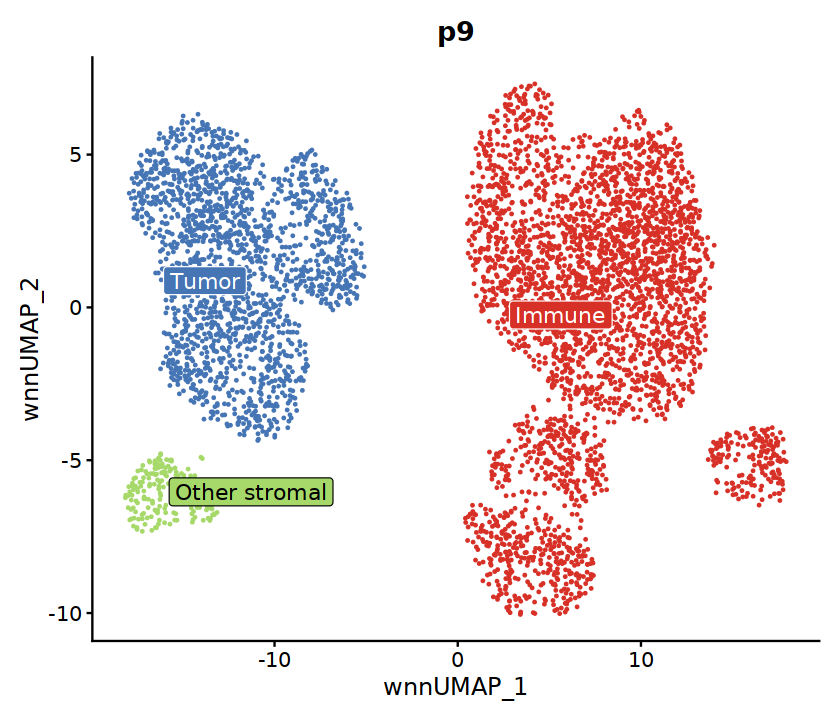

In [49]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [50]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [51]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [52]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

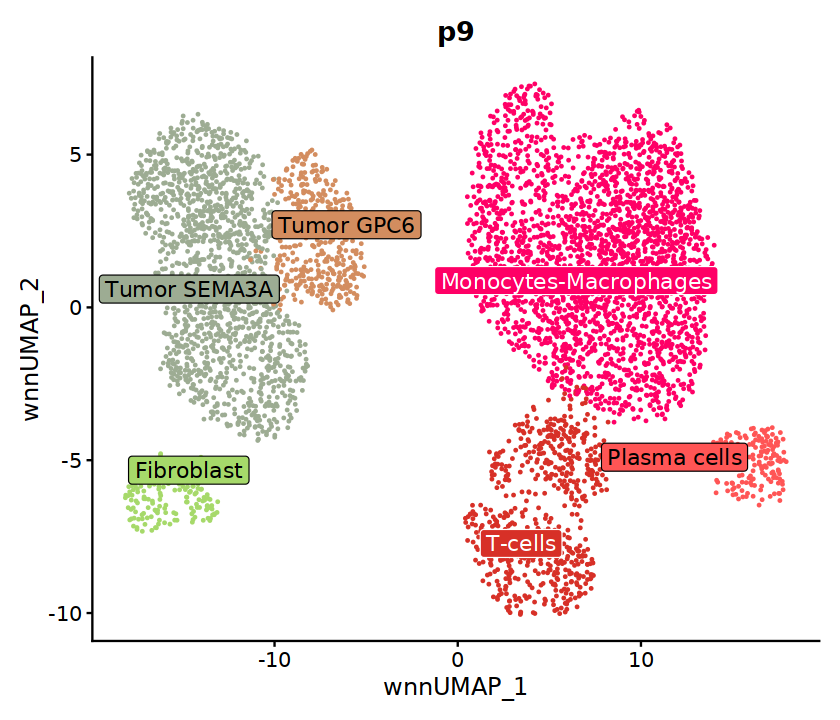

In [53]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [54]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

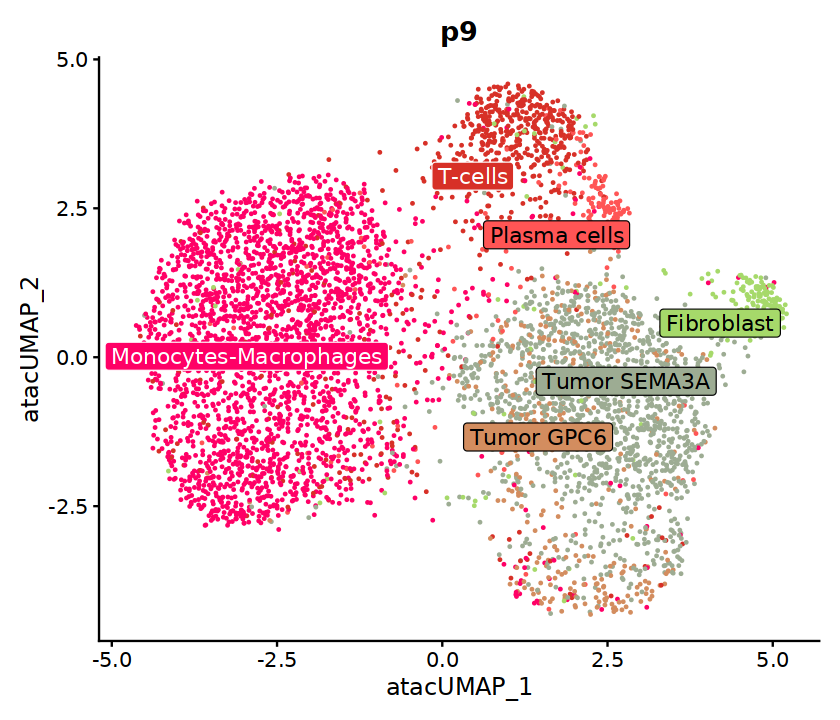

In [55]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [56]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

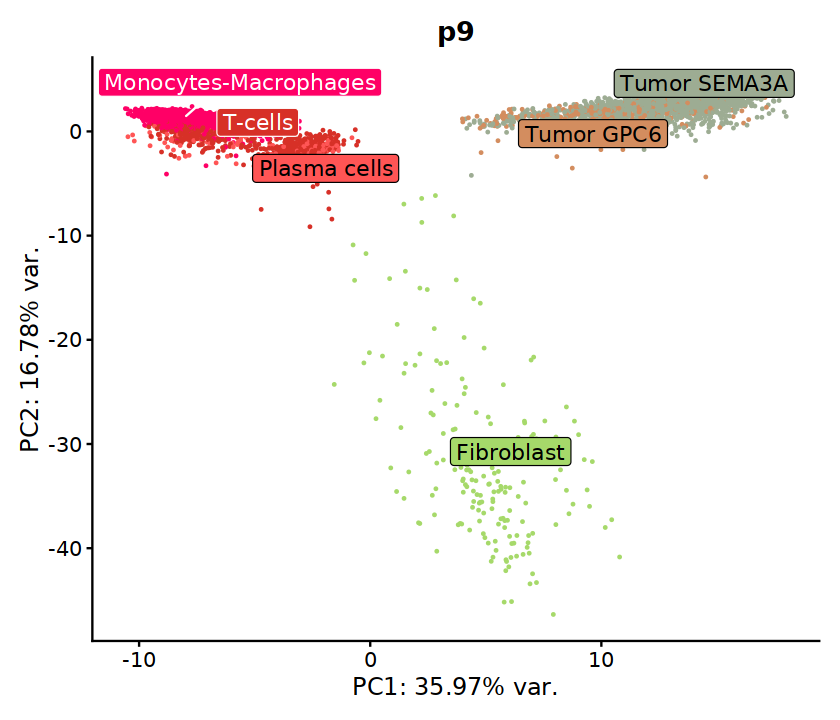

In [57]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

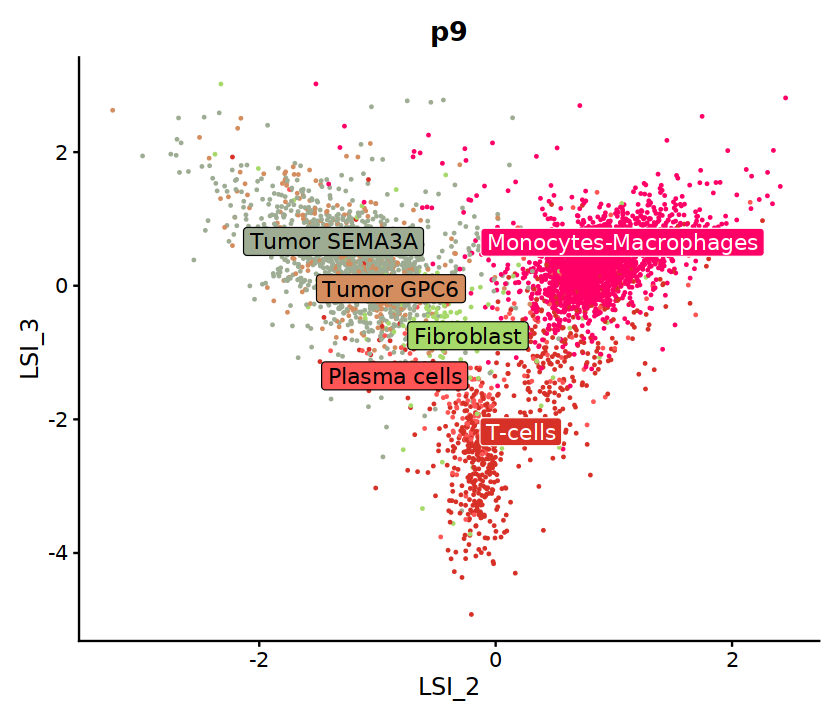

In [58]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

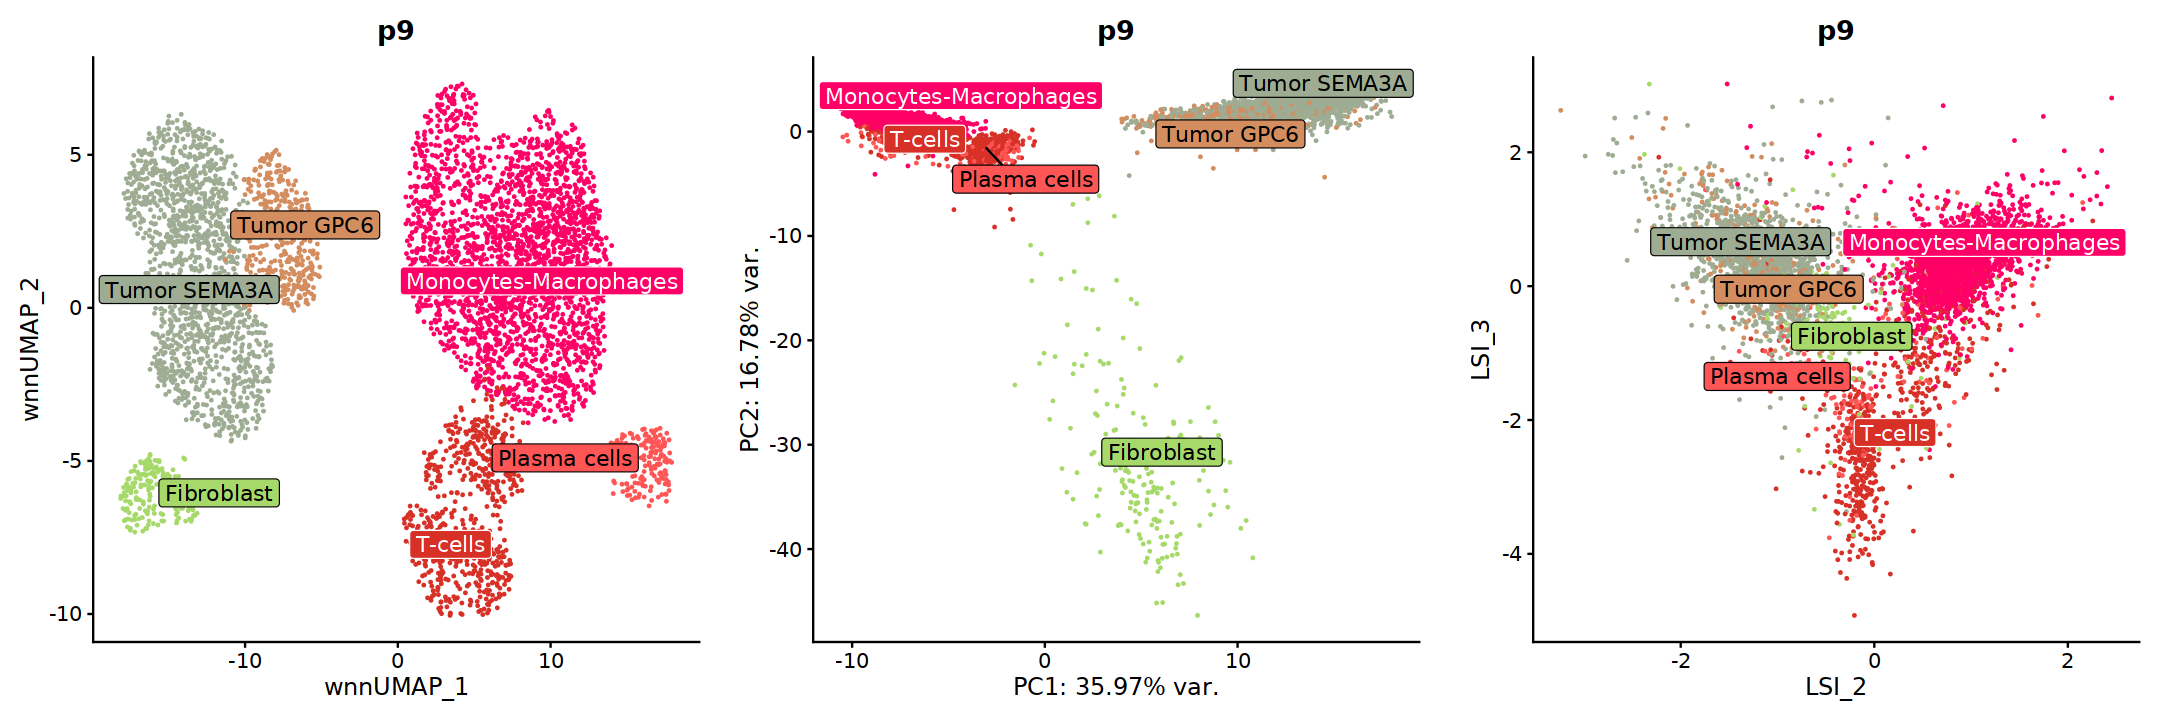

In [59]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [60]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [61]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEIS2", "ROBO1"), markers) ## common markers to all clusters

In [62]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

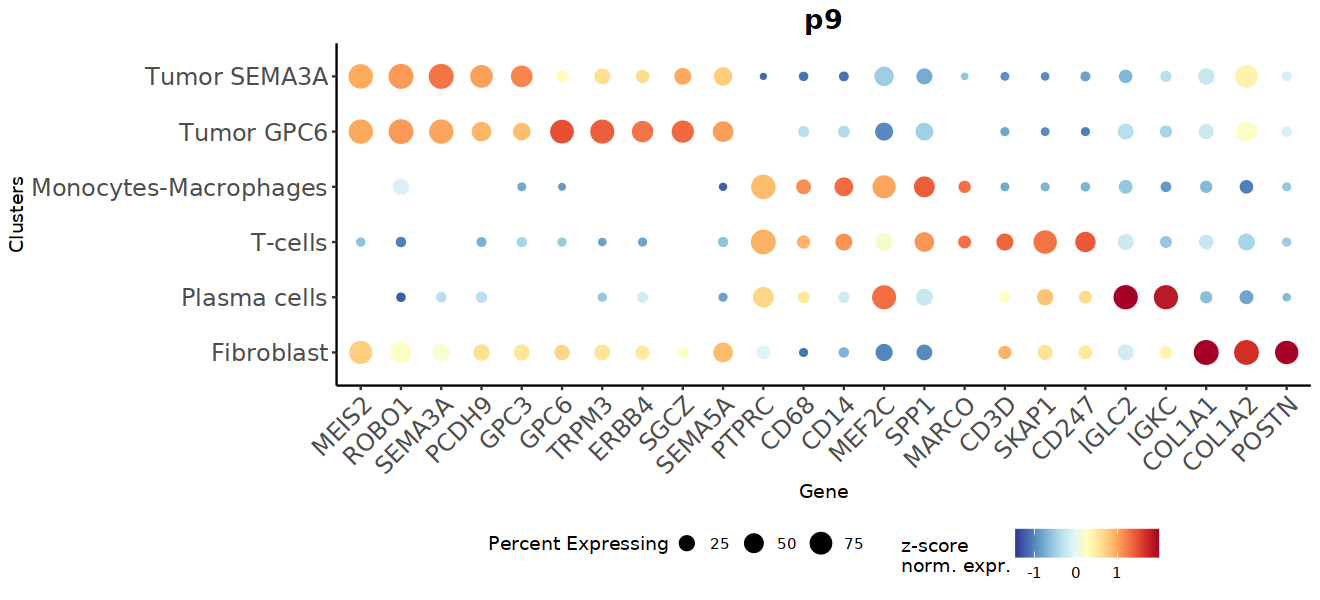

In [63]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

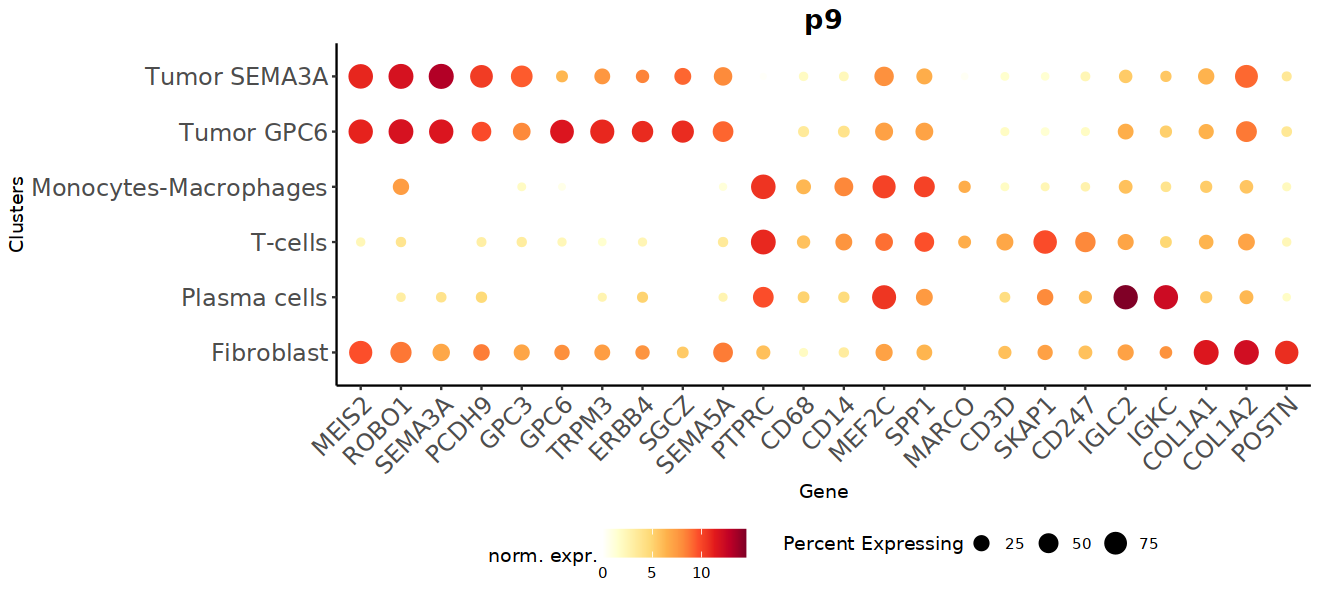

In [64]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [65]:
ggsave(plot = dp1, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

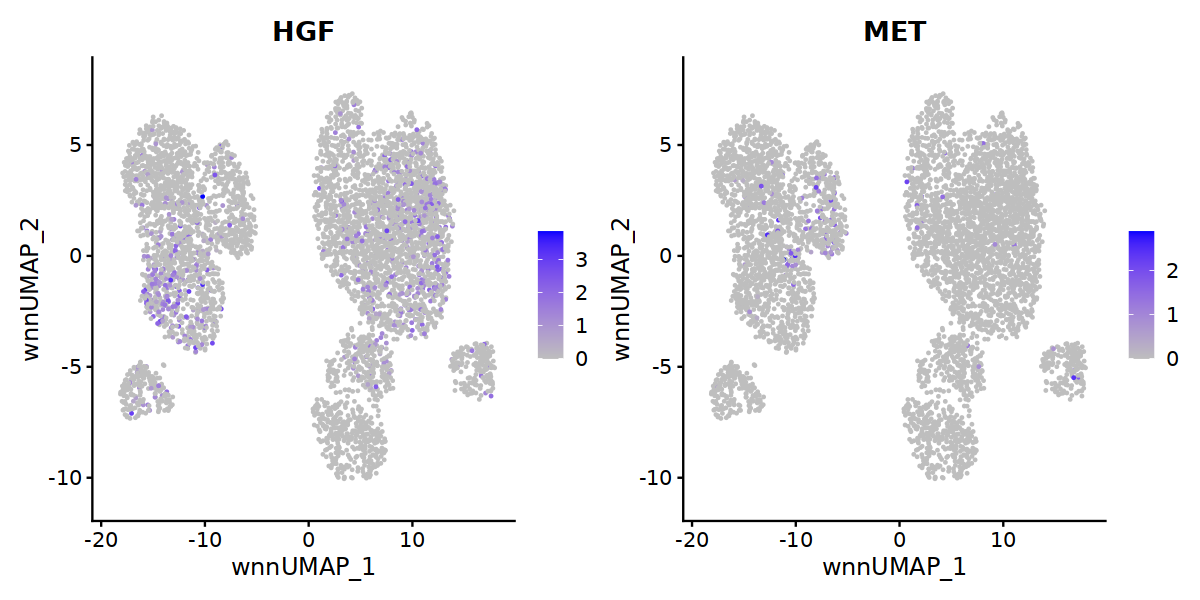

In [66]:
options(repr.plot.width = 10, repr.plot.height = 5)
hgf_met <- FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=c("HGF","MET"), ncol = 2, 
            cols = c("gray", "blue"),  min.cutoff = 0)
hgf_met

In [67]:
ggsave(plot = hgf_met, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_HGFMET.png")))

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


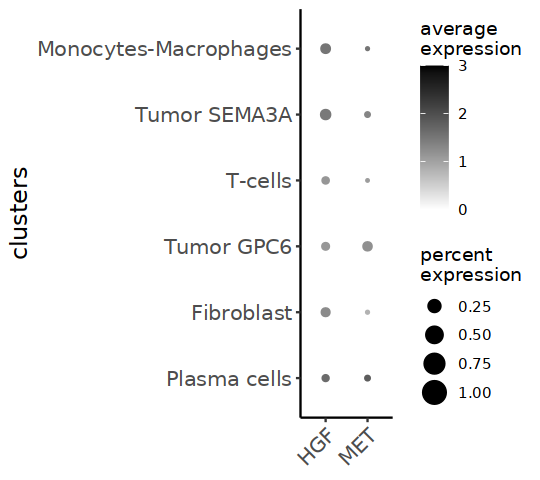

In [68]:
options(repr.plot.width = 4.5, repr.plot.height = 4, warn=-1,verbose = FALSE)
dp <- dittoSeq::dittoDotPlot(seurat_obj, vars=c("HGF", "MET"), 
                       group.by="clusters", scale=F, min.percent = 0.0001, max.percent = 1) + 
  theme(legend.position="right",axis.title.x = element_text(size = 14), 
  axis.title.y = element_text(size = 14),  
  axis.text.x = element_text(size = 12),   
  axis.text.y = element_text(size = 12)    
) +
  scale_y_discrete(limits=rev) + 
  scale_colour_gradient(low = "white", high = "black", name="average\nexpression",limits = c(0, 3)) +
  theme(legend.position = "right",
          legend.direction = "vertical") +
  guides(color = guide_colorbar(order = 1), 
       size = guide_legend(order = 2, ncol=1), ncol=1)
dp

In [69]:
ggsave(plot = dp, width = 4.5, height = 4, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_HGFMET_dotplot.png")))

## Save

In [70]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [71]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [72]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [73]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    